# Notebook 04 — Clusterização com K-Means: os dados se separam sozinhos? (dados novos)

**O que buscamos aqui:** descobrir o quanto as condições do ventilador (velocidade e falha) se separam **sem que o algoritmo saiba os rótulos**. Se os grupos aparecem sozinhos, a diferença entre as condições é real e forte, e um classificador treinado com rótulos (Notebook 05) tende a funcionar ainda melhor. Se não aparecem, entendemos **por quê** antes de treinar qualquer modelo.

**Os rótulos (velocidade e condição) ficam guardados à parte** e só entram no fim de cada experimento, para conferir o que o K-Means encontrou. A única exceção está explicada no Passo 4 (o scaler local "b").

## Sobre os dados desta versão (dados novos)

Esta é a versão do Notebook 04 para a pasta `NOVOS_DADOS`: **normal, fita 1g, papel e porca frouxa**, nas três velocidades, com a oscilação ligada. São 12 bases, uma por condição e velocidade. Como nos Notebooks 01 a 03, os primeiros e os últimos 5 s de cada base são descartados.

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1 | Configuração | Conjuntos de features, opções de log e scaler |
| 2 | Carregar as bases e calcular as 109 features | A mesma tabela dos Notebooks 02 e 03 |
| 3 | Transformação logarítmica | Reduzir a cauda comprida das features |
| 4 | Padronização (scaler) global e local | Colocar as features na mesma escala sem apagar o que importa |
| 5 | Como medir: matriz de confusão, acurácia, recall, precisão, ARI | Saber ler cada resultado |
| 6 | K=3 só no normal | O K-Means acha as 3 velocidades? |
| 7 | K=3 em cada falha | E com cada falha? |
| 8 | K=2 global | Separa normal de falha sem saber a velocidade? |
| 9 | K=2 em cada velocidade (scaler local) | O teste principal de detecção: **normal × cada falha** e **normal × todas as falhas** |
| 10 | K=12 | Velocidade e condição ao mesmo tempo (3 velocidades × 4 condições) |
| 11 | Silhueta | Os dados "pedem" quantos grupos, sem olhar rótulos? |
| 12 | Checagens anti-ilusão | Aquecimento, fase do ciclo, estabilidade, janelas atípicas |
| Resumo | Tabela final e decisões | O que levar para o Notebook 05 |

## O que é o K-Means (em uma linha)

Ele recebe as janelas como pontos num espaço de 109 dimensões (uma por feature), escolhe **K centros** e coloca cada janela no grupo do centro mais próximo, ajustando os centros até estabilizar. **Ele mede distância**, por isso a escala das features (Passos 3 e 4) muda tudo.

## Ressalvas que valem para todo o notebook

* **As falhas têm forças muito diferentes (Notebook 02):** a fita é forte, o papel é médio e a porca é fraca. O caso mais difícil é a **porca na Vel 2**, em que só 1 feature passou do teto do controle. Um bom resultado "geral" pode esconder a porca. Por isso o Passo 9 mostra **cada falha separada**.
* **Desbalanceamento:** existem 3 falhas e um normal, ou seja, cerca de **3 janelas com falha para cada janela normal**. Quando as falhas são juntadas, a acurácia engana (Passo 5).
* **Aquecimento (Notebook 03, Passo 7.3):** nas Vel 1 e 2, o começo e o fim de cada gravação são diferentes, porque o motor esquenta e a rotação sobe. O K-Means pode separar **"começo × fim"** em vez de **"normal × falha"**. O Passo 12 confere isso de duas formas: os erros ao longo do tempo (12.1) e o K=2 só no normal (12.2).
* **Ciclo da oscilação (Notebook 03, Passo 7.2.1):** dura cerca de 225 voltas da hélice, ou seja, cerca de 18 s na Vel 1, 12 s na Vel 2 e 10 s na Vel 3. Com janelas de 5 s, cada janela pega um pedaço diferente do ciclo.
* **Uma gravação por condição:** quando duas condições se separam, parte da diferença pode ser **da gravação**, e não da falha. Isso só se resolve testando em outra sessão (Notebook 05).
* **Não há divisão treino/teste aqui.** O K-Means não aprende rótulos, então não existe "decorar a resposta". Mas os scalers são ajustados nos próprios dados analisados. Isso serve para a **viabilidade**; no Notebook 05 os scalers serão ajustados **só no treino**.

## Como usar

1. Use a mesma pasta de bases dos notebooks anteriores. Com `BUSCAR_EM_SUBPASTAS = True`, as subpastas (`NORMAL`, `ANOMALIA`) também são lidas.
2. No Passo 1, confira `CONDICOES_REFERENCIA`. As falhas entram sozinhas, e o K do Passo 10 é calculado sozinho (velocidades × condições).
3. Rode em ordem. **Em cada passo, leia o texto antes do resultado.**

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte. Precisa de `scikit-learn` instalado.

## Passo 1 — Configuração

**O que buscamos:** concentrar num só lugar tudo o que muda de um experimento para outro. Os blocos "LOG", "SCALER" e "K-MEANS" são explicados nos Passos 3, 4 e 5.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, rankdata
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS (a mesma pasta dos notebooks anteriores)
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\NOVOS_DADOS")
BUSCAR_EM_SUBPASTAS = True        # True = lê também os CSVs dentro das subpastas (NORMAL, ANOMALIA)
DESCARTAR_INICIO_S = 5            # segundos descartados no começo de cada base (Notebook 01, Passo 4.1)
DESCARTAR_FIM_S = 5               # segundos descartados no fim de cada base

# ----------------------------------------------------------------------
# QUEM É REFERÊNCIA (NORMAL) E QUEM É ANOMALIA
# ----------------------------------------------------------------------
CONDICOES_REFERENCIA = ["ventilador_normal"]
CONDICOES_COMPARADAS = None                    # None = todas as outras condições da pasta
NOME_NORMAL = "normal"                         # rótulo usado nas matrizes para a referência
NOME_ANOMALIA = "anomalia"                     # rótulo binário das falhas (no K=2)

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000
EIXOS = ["x", "y", "z"]
UNIDADE = "m/s²"

# ----------------------------------------------------------------------
# JANELAS E FEATURES (a mesma receita do Notebook 02: 109 features)
# ----------------------------------------------------------------------
JANELA_S = 5
FAIXA_FFT_HZ = (5, 305)
LARGURA_FAIXA_HZ = 10
FAIXA_BUSCA_1X_HZ = (8, 30)
DESVIO_MAX_1X_HZ = 2.0
N_HARMONICAS = 3
TOLERANCIA_HARMONICA_HZ = 0.6

# ----------------------------------------------------------------------
# LOG (Passo 3)
# ----------------------------------------------------------------------
APLICAR_LOG = True
COLUNAS_SEM_LOG = ["kurt_x", "kurt_y", "kurt_z"]   # a curtose pode ser negativa: não aceita log

# ----------------------------------------------------------------------
# K-MEANS
# ----------------------------------------------------------------------
N_INIT = 20                       # o K-Means recomeça 20 vezes de pontos diferentes e fica com o melhor resultado
SEMENTE = 42                      # fixa os sorteios para o resultado ser sempre igual
CONJUNTO_PRINCIPAL = "todas"      # conjunto de features mostrado nas matrizes (os outros aparecem nas tabelas)
K_SILHUETA = range(2, 9)          # valores de K testados na silhueta (Passo 11)
N_SEMENTES_ESTABILIDADE = 10      # quantas sementes diferentes no teste de estabilidade (Passo 12)

# ----------------------------------------------------------------------
# JANELAS ATÍPICAS (Passo 12, mesmo critério do Notebook 03)
# ----------------------------------------------------------------------
LIMITE_Z_ROBUSTO = 8
MIN_FEATURES_ATIPICAS = 10

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
CORES_VELOCIDADE = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}
MARCADORES_CONDICAO = ["o", "X", "s", "^", "D", "P"]   # um por condição, na ordem: referência, depois as anomalias

## Passo 2 — Carregar as bases e calcular as 109 features

**O que buscamos:** a mesma tabela dos Notebooks 02 e 03. **O código desta parte é copiado do Notebook 02 sem alterações**, para garantir que as features são idênticas.

In [3]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome 'fita_1g_vel_2' em condição ('fita_1g') e velocidade (2)."""
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(
            f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N>, por exemplo 'fita_1g_vel_2'."
        )
    return encontrado["condicao"], int(encontrado["velocidade"])


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo), ordenados por condição e velocidade."""
    arquivos = sorted(Path(pasta).rglob("*.csv") if BUSCAR_EM_SUBPASTAS else Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES.")
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({
            "base": nome,
            "condicao": condicao,
            "velocidade": velocidade,
            "linhas": len(bases[nome]),
            "duracao_s": len(bases[nome]) / TAXA_AMOSTRAGEM_HZ,
        })
    catalogo = pd.DataFrame(linhas).sort_values(["condicao", "velocidade"]).set_index("base")
    bases = {nome: bases[nome] for nome in catalogo.index}
    return bases, catalogo



def aparar_bases(bases, catalogo, inicio_s=DESCARTAR_INICIO_S, fim_s=DESCARTAR_FIM_S):
    """Descarta inicio_s segundos do começo e fim_s do fim de cada base (o mesmo corte do Notebook 01)."""
    inicio, fim = int(inicio_s * TAXA_AMOSTRAGEM_HZ), int(fim_s * TAXA_AMOSTRAGEM_HZ)
    aparadas = {nome: df.iloc[inicio: len(df) - fim].reset_index(drop=True) for nome, df in bases.items()}
    catalogo = catalogo.copy()
    catalogo["linhas"] = [len(aparadas[nome]) for nome in catalogo.index]
    catalogo["duracao_s"] = catalogo["linhas"] / TAXA_AMOSTRAGEM_HZ
    return aparadas, catalogo


def definir_comparacoes(catalogo, condicoes_referencia, condicoes_comparadas=None):
    """Confere a referência e devolve a lista de condições que serão comparadas com ela."""
    existentes = sorted(catalogo["condicao"].unique())
    faltando = [c for c in condicoes_referencia if c not in existentes]
    if faltando:
        raise ValueError(f"Condição de referência não encontrada: {faltando}. Condições na pasta: {existentes}")
    if condicoes_comparadas is None:
        condicoes_comparadas = [c for c in existentes if c not in condicoes_referencia]
    faltando = [c for c in condicoes_comparadas if c not in existentes]
    if faltando:
        raise ValueError(f"Condição comparada não encontrada: {faltando}. Condições na pasta: {existentes}")
    if not condicoes_comparadas:
        raise ValueError(
            "Não há nenhuma condição para comparar com a referência. "
            "Coloque na pasta as bases da anomalia (por exemplo fita_1g_vel_1.csv)."
        )
    return list(condicoes_comparadas)


def resumir_catalogo(catalogo):
    """Número de bases e total de segundos por condição e velocidade."""
    return catalogo.groupby(["condicao", "velocidade"]).agg(bases=("linhas", "size"), duracao_s=("duracao_s", "sum"))


def avisar_velocidades_sem_referencia(catalogo, condicoes_referencia, condicoes_comparadas):
    """Avisa quando uma condição comparada tem uma velocidade que a referência não tem."""
    velocidades_ref = set(catalogo.loc[catalogo["condicao"].isin(condicoes_referencia), "velocidade"])
    for condicao in condicoes_comparadas:
        velocidades = set(catalogo.loc[catalogo["condicao"] == condicao, "velocidade"])
        sem_ref = sorted(velocidades - velocidades_ref)
        if sem_ref:
            print(f"ATENÇÃO: '{condicao}' tem as velocidades {sem_ref}, que a referência não tem. Elas ficarão sem comparação.")

In [4]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
bases, catalogo = aparar_bases(bases, catalogo)
condicoes_comparadas = definir_comparacoes(catalogo, CONDICOES_REFERENCIA, CONDICOES_COMPARADAS)
velocidades = sorted(catalogo["velocidade"].unique())

print(f"Referência: {CONDICOES_REFERENCIA}")
print(f"Comparadas: {condicoes_comparadas}")
avisar_velocidades_sem_referencia(catalogo, CONDICOES_REFERENCIA, condicoes_comparadas)
display(resumir_catalogo(catalogo))

Referência: ['ventilador_normal']
Comparadas: ['fita_1g', 'papel', 'porca_frouxa']


bases  duracao_s
condicao          velocidade                  
fita_1g           1               1    619.500
                  2               1    647.000
                  3               1    633.500
papel             1               1    629.000
                  2               1    633.000
                  3               1    642.500
porca_frouxa      1               1    638.000
                  2               1    638.492
                  3               1    640.500
ventilador_normal 1               1    636.000
                  2               1    647.500
                  3               1    623.500

In [5]:
def faixas_de_frequencia():
    """Lista de faixas (início, fim) em Hz, como (5, 15), (15, 25), ..., (295, 305)."""
    limites = np.arange(FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1] + LARGURA_FAIXA_HZ, LARGURA_FAIXA_HZ)
    return [(int(inicio), int(fim)) for inicio, fim in zip(limites[:-1], limites[1:])]


def colunas_fft_do_eixo(eixo):
    """Nomes das colunas de FFT de um eixo, na ordem das faixas."""
    return [f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}" for inicio, fim in faixas_de_frequencia()]


def calcular_features_e_espectros(df, janela_s=JANELA_S):
    """Corta a base em janelas sem sobreposição e calcula as features de cada janela.

    A última janela incompleta é descartada. Devolve (features, frequencias, espectros):
      features: uma linha por janela, com as colunas std_x, kurt_x, pico_x, ..., fft_005_015Hz_x, ...
      frequencias: eixo de frequências (Hz), de FAIXA_FFT_HZ[0] até FAIXA_FFT_HZ[1]
      espectros: magnitude de cada janela, no formato (janela, frequência, eixo)
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    dados = df[EIXOS].to_numpy()[: n_janelas * tamanho]
    janelas = dados.reshape(n_janelas, tamanho, len(EIXOS))        # (janela, amostra, eixo)
    janelas = janelas - janelas.mean(axis=1, keepdims=True)         # remove o componente DC de cada janela

    colunas = {}
    std = janelas.std(axis=1, ddof=1)
    curtose = kurtosis(janelas, axis=1, fisher=True)
    pico = np.abs(janelas).max(axis=1)
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"] = std[:, k]
        colunas[f"kurt_{eixo}"] = curtose[:, k]
        colunas[f"pico_{eixo}"] = pico[:, k]

    # FFT com janela de Hanning; o fator 4/N compensa a energia que a janela remove
    janela_hanning = np.hanning(tamanho)[None, :, None]
    magnitude = np.abs(np.fft.rfft(janelas * janela_hanning, axis=1)) * (4.0 / tamanho)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)

    for inicio, fim in faixas_de_frequencia():
        na_faixa = (frequencias >= inicio) & (frequencias < fim)
        maximo_da_faixa = magnitude[:, na_faixa, :].max(axis=1)     # (janela, eixo)
        for k, eixo in enumerate(EIXOS):
            colunas[f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}"] = maximo_da_faixa[:, k]

    no_intervalo = (frequencias >= FAIXA_FFT_HZ[0]) & (frequencias < FAIXA_FFT_HZ[1])
    return pd.DataFrame(colunas), frequencias[no_intervalo], magnitude[:, no_intervalo, :]


def analisar_todas_as_bases(bases, catalogo, janela_s=JANELA_S):
    """Calcula as features de todas as bases e junta numa só tabela.

    Devolve (features, frequencias, espectros_por_base). A tabela tem as colunas
    base, condicao, velocidade e janela (posição da janela dentro da base), mais as 99 features.
    """
    tabelas, espectros_por_base, frequencias = [], {}, None
    for nome, df in bases.items():
        features, frequencias, espectros = calcular_features_e_espectros(df, janela_s)
        features.insert(0, "janela", np.arange(len(features)))
        features.insert(0, "velocidade", catalogo.loc[nome, "velocidade"])
        features.insert(0, "condicao", catalogo.loc[nome, "condicao"])
        features.insert(0, "base", nome)
        tabelas.append(features)
        espectros_por_base[nome] = espectros
    return pd.concat(tabelas, ignore_index=True), frequencias, espectros_por_base

In [6]:
def estimar_f1x(frequencias, espectros):
    """Rotação 1X de cada janela, em duas passadas.

    1ª passada: pico da soma dos três eixos dentro de FAIXA_BUSCA_1X_HZ, janela por janela.
    A mediana dessas janelas é a rotação típica da base.
    2ª passada: repete a busca, mas só a até DESVIO_MAX_1X_HZ da rotação típica. Isso evita que, numa
    anomalia forte, o pico do 2X ou de outra frequência seja confundido com o 1X.
    """
    soma_dos_eixos = espectros.sum(axis=2)                                         # (janela, frequência)
    na_faixa = (frequencias >= FAIXA_BUSCA_1X_HZ[0]) & (frequencias <= FAIXA_BUSCA_1X_HZ[1])
    primeira = frequencias[na_faixa][soma_dos_eixos[:, na_faixa].argmax(axis=1)]
    tipica = np.median(primeira)
    perto = na_faixa & (np.abs(frequencias - tipica) <= DESVIO_MAX_1X_HZ)
    return frequencias[perto][soma_dos_eixos[:, perto].argmax(axis=1)]


def medir_amplitudes_harmonicas(frequencias, espectros, f1x, n_harmonicas, tolerancia_hz):
    """Amplitude de 1X, 2X, ... em cada janela e eixo: o maior pico a até tolerancia_hz de k vezes o 1X."""
    colunas = {}
    for k in range(1, n_harmonicas + 1):
        alvo = k * f1x                                                           # (janela,)
        perto = np.abs(frequencias[None, :] - alvo[:, None]) <= tolerancia_hz     # (janela, frequência)
        for j, eixo in enumerate(EIXOS):
            colunas[f"amp_{k}x_{eixo}"] = np.where(perto, espectros[:, :, j], 0.0).max(axis=1)
    return pd.DataFrame(colunas)


def adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base):
    """Acrescenta à tabela a rotação (f1x_hz) e as amplitudes amp_1x_x, amp_2x_x, ... de cada janela."""
    features = features.drop(columns=[c for c in features.columns if c.startswith("amp_") or c == "f1x_hz"])
    partes = []
    for nome, grupo in features.groupby("base", sort=False):
        espectros = espectros_por_base[nome]
        f1x = estimar_f1x(frequencias, espectros)
        amplitudes = medir_amplitudes_harmonicas(frequencias, espectros, f1x, N_HARMONICAS, TOLERANCIA_HARMONICA_HZ)
        amplitudes.insert(0, "f1x_hz", f1x)
        amplitudes.index = grupo.index
        partes.append(amplitudes)
    return features.join(pd.concat(partes))

In [7]:
features, frequencias, espectros_por_base = analisar_todas_as_bases(bases, catalogo)
features = adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base)

COLUNAS_TEMPO = [f"{tipo}_{eixo}" for tipo in ("std", "kurt", "pico") for eixo in EIXOS]
COLUNAS_FFT = [coluna for eixo in EIXOS for coluna in colunas_fft_do_eixo(eixo)]
COLUNAS_ROTACAO = [f"amp_{k}x_{eixo}" for k in range(1, N_HARMONICAS + 1) for eixo in EIXOS] + ["f1x_hz"]
COLUNAS_TODAS = COLUNAS_TEMPO + COLUNAS_FFT + COLUNAS_ROTACAO
CONJUNTOS = {"tempo": COLUNAS_TEMPO, "FFT": COLUNAS_FFT, "rotação": COLUNAS_ROTACAO, "todas": COLUNAS_TODAS}

print(f"{len(COLUNAS_TODAS)} features: {len(COLUNAS_TEMPO)} de tempo + {len(COLUNAS_FFT)} de FFT + {len(COLUNAS_ROTACAO)} de rotação")

109 features: 9 de tempo + 90 de FFT + 10 de rotação


### 2.1 — O gabarito, guardado à parte

**O que buscamos:** separar a **matriz de features** (o que o K-Means vê) do **gabarito** (o que só usamos para conferir). O gabarito tem, para cada janela:

* `velocidade`: 1, 2 ou 3;
* `binario`: `normal` ou `anomalia` (para o K=2);
* `classe`: condição + velocidade, por exemplo `fita_1g V2` (para o K=12);
* `condicao`: o nome da condição, como no arquivo.

In [8]:
def montar_gabarito(features, condicoes_ref):
    """Tabela com os rótulos de cada janela. Não entra em nenhum K-Means, só na avaliação."""
    eh_normal = features["condicao"].isin(condicoes_ref)
    nome_condicao = np.where(eh_normal, NOME_NORMAL, features["condicao"])
    return pd.DataFrame({
        "base": features["base"],
        "janela": features["janela"],
        "velocidade": features["velocidade"],
        "condicao": nome_condicao,
        "binario": np.where(eh_normal, NOME_NORMAL, NOME_ANOMALIA),
        "classe": [f"{c} V{v}" for c, v in zip(nome_condicao, features["velocidade"])],
    }, index=features.index)

In [9]:
gabarito = montar_gabarito(features, CONDICOES_REFERENCIA)
ORDEM_CONDICOES = [NOME_NORMAL] + [c for c in condicoes_comparadas]
ORDEM_CLASSES = [f"{c} V{v}" for v in velocidades for c in ORDEM_CONDICOES if f"{c} V{v}" in set(gabarito["classe"])]

print("Janelas por classe:")
display(gabarito.groupby(["velocidade", "condicao"]).size().unstack().reindex(columns=ORDEM_CONDICOES))

Janelas por classe:


condicao,normal,fita_1g,papel,porca_frouxa
velocidade,,,,
1,127,123,125,127
2,129,129,126,127
3,124,126,128,128


## Passo 3 — Transformação logarítmica

**O que é:** trocar cada valor `x` pelo seu logaritmo natural, `log(x)`.

**O que faz, com números:** o log "encolhe" valores grandes e "estica" os pequenos.

| Valor original | log |
| --- | --- |
| 0,1 | −2,3 |
| 1 | 0 |
| 10 | 2,3 |
| 100 | 4,6 |

Repare: de 1 para 10 e de 10 para 100 o log anda **o mesmo tanto** (2,3). Ou seja, depois do log **"dez vezes maior" vira uma distância fixa**, não importa se o valor é pequeno ou grande.

**Por que isso importa para o K-Means:**

* **Cauda comprida.** O Notebook 03 mostrou que as features de FFT têm algumas janelas com valores muito altos. Sem log, essas poucas janelas puxam as distâncias e os centros dos grupos. Com log, elas viram pontos comuns.
* **Falhas são multiplicativas.** Nos dados novos, a fita na Vel 2 aumenta `std_x` de 1,88 para 9,40 m/s² (5 vezes), e na Vel 1 de 0,49 para 0,84 m/s² (1,7 vez) (Notebook 02). Sem log, a diferença da Vel 1 (0,35) parece minúscula perto da da Vel 2 (7,5): mais de 20 vezes menor. Com log, elas viram distâncias de 0,54 e 1,61, só 3 vezes menor, e a falha da Vel 1 deixa de ser "abafada".

**Em quais features aplicamos:** em todas, **menos a curtose** (`kurt_x`, `kurt_y`, `kurt_z`). A curtose pode ser negativa ou zero, e o log não existe para esses valores. As demais são sempre positivas (o código confere).

**Vazamento de dados?** Não. O log é a mesma conta para qualquer janela, não "aprende" nada dos dados. Num modelo em produção, basta aplicar o mesmo `log` nas janelas novas.

> **Diferença em relação ao Notebook 03:** nos dados novos, o log **piorou** a assimetria das features de rotação (`amp_kx` e `f1x_hz`; tortas de 22% para 39%), e ajudou muito nas FFT (tortas de 42% para 16%). Aqui seguimos a decisão do grupo de aplicar em tudo menos a curtose, porque o K-Means se importa com escala e extremos, e não com o formato de sino. A variação "sem log na rotação" fica para testar no Notebook 05. Se quiser voltar atrás, acrescente as colunas de rotação em `COLUNAS_SEM_LOG` no Passo 1.

In [10]:
def aplicar_log(features, colunas, colunas_sem_log=COLUNAS_SEM_LOG, aplicar=APLICAR_LOG):
    """Devolve a matriz das colunas pedidas, com log natural em todas menos colunas_sem_log."""
    matriz = features[colunas].astype(float).copy()
    if not aplicar:
        return matriz
    com_log = [c for c in colunas if c not in colunas_sem_log]
    nao_positivas = [c for c in com_log if (matriz[c] <= 0).any()]
    if nao_positivas:
        raise ValueError(f"Estas colunas têm valores <= 0 e não aceitam log: {nao_positivas}")
    matriz[com_log] = np.log(matriz[com_log])
    return matriz

In [11]:
matriz_log = aplicar_log(features, COLUNAS_TODAS)
print(f"Log aplicado em {len(COLUNAS_TODAS) - len(COLUNAS_SEM_LOG)} features; sem log: {COLUNAS_SEM_LOG}")

Log aplicado em 106 features; sem log: ['kurt_x', 'kurt_y', 'kurt_z']


## Passo 4 — Padronização (scaler): global ou local?

**O que é o StandardScaler:** para cada feature, subtrai a média e divide pelo desvio padrão:

`z = (x − média) / desvio`

Depois disso, toda feature tem média 0 e desvio 1. O valor `z` diz **"quantos desvios essa janela está longe da média"**.

**Por que padronizar:** o K-Means mede distância. Sem padronizar, uma feature que vai de 0 a 25 m/s² (`pico_y`) pesaria muito mais que uma que vai de 0 a 0,1 (uma faixa fraca da FFT), só por causa da unidade. A padronização dá a todas o mesmo peso.

**A pergunta importante: média e desvio de quais janelas?**

### Scaler global: uma média e um desvio para todo o conjunto

Junta todas as velocidades e condições e calcula uma média só.

**Problema: esconde as diferenças pequenas atrás das grandes.** Exemplo com `std_y`: o desvio padrão global é dominado pela diferença entre velocidades e pela fita da Vel 2 e 3, que vibram muito. A diferença entre normal e fita **dentro da Vel 1** vira uma fração pequena desse desvio global. Para o K-Means, as janelas da Vel 1, normais ou com fita, parecem quase iguais. **Foi exatamente isso que fez o K=2 global falhar na Vel 1 nos dados antigos (0 de 112 janelas da fita detectadas).** O Passo 8 mostra o que acontece nos dados novos.

**Quando o global é o certo:** quando queremos **justamente** as diferenças grandes. Para achar as velocidades (Passos 6 e 7), a magnitude é a informação, então usamos o global.

### Scaler local: uma média e um desvio para cada velocidade

Cada velocidade é padronizada separadamente. Assim o K-Means vê **o que muda dentro da velocidade**, e a Vel 1 deixa de ser abafada pelas outras. Há duas formas de escolher as janelas que definem a média e o desvio:

| | **(a) Local com todas as janelas** | **(b) Local só com o Normal (principal)** |
| --- | --- | --- |
| Média e desvio vêm de | todas as janelas da velocidade (normal + falha) | só as janelas **normais** da velocidade |
| Usa rótulo? | só a velocidade | a velocidade **e** quem é normal |
| O que `z` significa | distância da média da mistura | **quantos desvios a janela está longe do normal** |
| Problema | o resultado depende da proporção de falha nos dados; com muita falha, a "média" já fica contaminada | precisa de uma gravação de referência do ventilador saudável |
| Como seria em produção | difícil: não se sabe a mistura de antemão | natural: grava-se o ventilador bom na instalação (calibração), e tudo o que foge disso é suspeito |
| Como nos notebooks antigos? | **sim** | não |

**Por que a (b) é a principal:** ela imita a arquitetura planejada (um modelo que conhece bem o normal e acusa o que foge dele). A (a) fica para comparar com os resultados antigos.

**Sobre "usa rótulo":** o scaler local precisa saber a velocidade de cada janela. No Passo 10 mostramos uma versão em que a velocidade é **descoberta** pelo K-Means (K=3), sem rótulo.

**O gráfico abaixo** mostra uma feature (`std_y`, depois do log) em três versões: original, padronizada globalmente e padronizada localmente (b). Repare como no global a Vel 1 fica espremida, e no local (b) o normal de cada velocidade fica em volta de zero, com a falha bem afastada.

In [12]:
def padronizar_global(matriz):
    """StandardScaler com uma média e um desvio para todas as janelas."""
    return pd.DataFrame(StandardScaler().fit_transform(matriz), index=matriz.index, columns=matriz.columns)


def padronizar_local(matriz, grupos, janelas_de_ajuste):
    """StandardScaler separado por grupo (normalmente a velocidade).

    grupos: o grupo de cada janela.
    janelas_de_ajuste: True nas janelas usadas para calcular a média e o desvio de cada grupo.
      - scaler local (a): todas as janelas  -> janelas_de_ajuste = True em tudo
      - scaler local (b): só as normais     -> janelas_de_ajuste = (gabarito["binario"] == NOME_NORMAL)
    Todas as janelas do grupo são transformadas com a média e o desvio calculados.
    """
    padronizada = pd.DataFrame(index=matriz.index, columns=matriz.columns, dtype=float)
    for grupo in pd.unique(grupos):
        no_grupo = (grupos == grupo).to_numpy()
        ajuste = no_grupo & np.asarray(janelas_de_ajuste)
        scaler = StandardScaler().fit(matriz[ajuste])
        padronizada.loc[no_grupo] = scaler.transform(matriz[no_grupo])
    return padronizada


def padronizar(matriz, gabarito, tipo):
    """Atalho para os três tipos de scaler: 'global', 'local_a' ou 'local_b'."""
    if tipo == "global":
        return padronizar_global(matriz)
    if tipo == "local_a":
        return padronizar_local(matriz, gabarito["velocidade"], np.ones(len(matriz), dtype=bool))
    if tipo == "local_b":
        return padronizar_local(matriz, gabarito["velocidade"], (gabarito["binario"] == NOME_NORMAL).to_numpy())
    raise ValueError(tipo)

In [13]:
def plotar_efeito_do_scaler(matriz, gabarito, feature):
    """Caixas da mesma feature por classe: depois do log, com scaler global e com scaler local (b)."""
    versoes = [
        ("Depois do log (sem padronizar)", matriz[[feature]]),
        ("Scaler global", padronizar_global(matriz)[[feature]]),
        ("Scaler local (b): ajustado só no normal de cada velocidade", padronizar(matriz, gabarito, "local_b")[[feature]]),
    ]
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
    for ax, (titulo, tabela) in zip(axs, versoes):
        dados = [tabela.loc[gabarito["classe"] == classe, feature].to_numpy() for classe in ORDEM_CLASSES]
        caixas = ax.boxplot(dados, patch_artist=True, widths=0.6)
        for caixa, classe in zip(caixas["boxes"], ORDEM_CLASSES):
            velocidade = int(classe.split("V")[-1])
            caixa.set_facecolor(CORES_VELOCIDADE.get(velocidade, "gray"))
            caixa.set_alpha(0.35 if classe.startswith(NOME_NORMAL) else 0.85)
        ax.set_xticks(range(1, len(ORDEM_CLASSES) + 1))
        ax.set_xticklabels(ORDEM_CLASSES, rotation=35, ha="right", fontsize=8)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(titulo, fontsize=10, fontweight="bold")
    axs[0].set_ylabel(f"{feature} (log)")
    axs[1].set_ylabel("z (desvios da média)")
    fig.suptitle(f"Efeito do scaler em {feature} — caixas claras = normal, escuras = anomalia", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

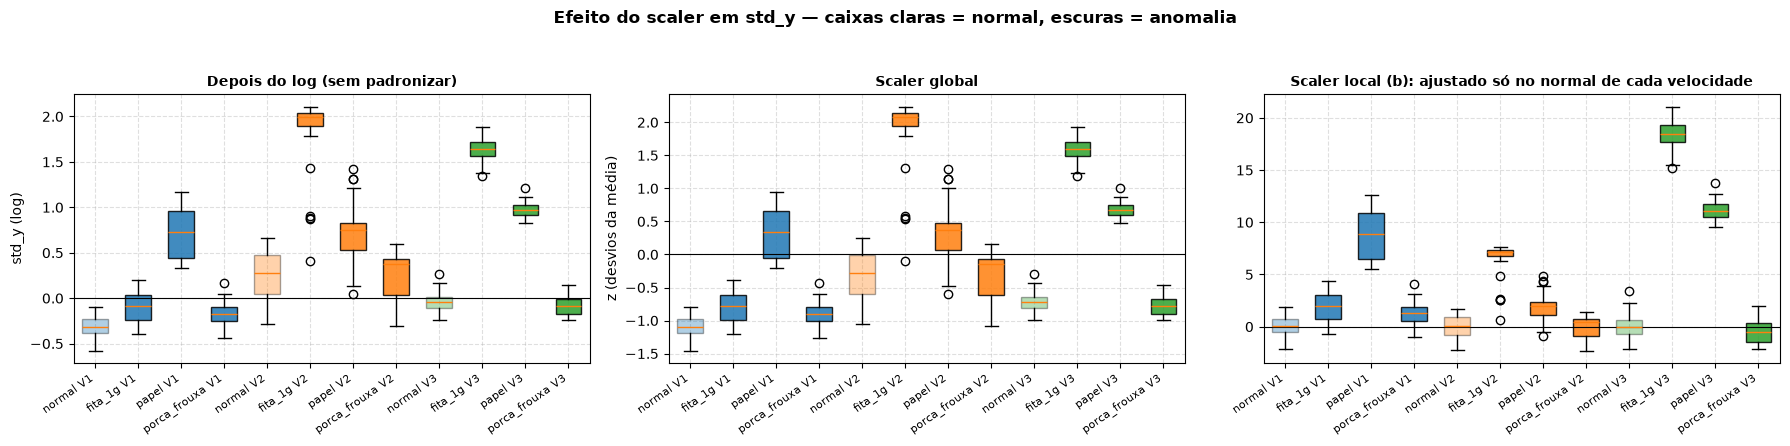

In [14]:
plotar_efeito_do_scaler(matriz_log, gabarito, "std_y")

### O que o gráfico mostra (nesta execução)

O gráfico mostra o `std_y`, depois do log, em três versões.

* **Depois do log (esquerda):** cada velocidade fica num "andar" diferente. A **fita** e o **papel** sobem bastante nas três velocidades. A **porca** fica quase em cima do normal.
* **Scaler global (meio):** o desenho é o mesmo, só muda a régua. A diferença entre **normal V1** e **porca V1** é uma fração pequena da régua, que é dominada pela fita V2 e V3.
* **Scaler local (b) (direita):** o normal de cada velocidade fica centrado em zero. Cada falha aparece como **quantos desvios do normal** ela está:
  * a fita V3 fica a cerca de 18 desvios do normal, e o papel V1 a cerca de 9;
  * a **fita V2 fica a só cerca de 7**, menos que na Vel 3, apesar de vibrar mais em m/s². O motivo é que o **normal V2 é mais espalhado** (a caixa clara da V2 é a mais larga do gráfico da esquerda). Um normal espalhado aumenta o desvio e diminui o `z` de qualquer falha. É o aquecimento de novo;
  * a **porca** continua perto de zero nas três velocidades: no `std_y`, ela quase não se distingue do normal.

## Passo 5 — Como medir: matriz de confusão, acurácia, recall, precisão e ARI

**O que buscamos:** saber ler cada resultado sem se enganar. Esta é a parte que o orientador mais vai olhar.

### 5.1 — Primeiro problema: o K-Means não sabe nomes

O K-Means devolve números de grupo (0, 1, 2...), não "normal" ou "fita". O grupo 0 pode ser a fita numa execução e o normal em outra. Para comparar com os rótulos, **associamos cada grupo à classe com que ele mais se sobrepõe**, de forma que cada classe receba um grupo diferente e o total de acertos seja o maior possível. Esse é o **método húngaro** (`linear_sum_assignment`). Se houver mais grupos que classes, os grupos que sobram vão para a classe majoritária deles.

### 5.2 — A matriz de confusão

Uma tabela que cruza **o que a janela é de verdade** (linhas) com **o que o K-Means disse** (colunas). Exemplo inventado, só para ilustrar, com 100 janelas normais e 100 com fita:

| | disse **normal** | disse **fita** |
| --- | --- | --- |
| **é normal** | 95 (acerto) | 5 (falso alarme) |
| **é fita** | 10 (falha não detectada) | 90 (acerto) |

* **Diagonal** (95 e 90): acertos.
* **Fora da diagonal:** erros. Os 5 são **falsos alarmes** (normal acusado como fita) e os 10 são **falhas que passaram despercebidas**.

Nos gráficos deste notebook, cada célula mostra a contagem e, embaixo, a **porcentagem da linha**. A porcentagem da diagonal é o recall daquela classe.

### 5.3 — As métricas, com o mesmo exemplo

| Métrica | O que responde | Conta | No exemplo |
| --- | --- | --- | --- |
| **Acurácia** | De todas as janelas, quantas o K-Means acertou? | acertos ÷ total | (95 + 90) ÷ 200 = **92,5%** |
| **Recall da fita** (sensibilidade, taxa de detecção) | Das janelas que **são** fita, quantas foram detectadas? | 90 ÷ (90 + 10) | **90%** |
| **Recall do normal** (especificidade) | Das janelas que **são** normais, quantas foram reconhecidas como normais? | 95 ÷ (95 + 5) | **95%** |
| **Taxa de falso alarme** | Das normais, quantas foram acusadas de falha? | 5 ÷ 100 = 1 − recall do normal | **5%** |
| **Precisão da fita** | Quando o K-Means disse "fita", quantas vezes era mesmo fita? | 90 ÷ (90 + 5) | **94,7%** |
| **ARI** | O agrupamento bate com a realidade, descontando o acaso? | ver abaixo | — |

**Por que o recall é a métrica mais importante para manutenção:** uma falha não detectada (recall baixo) significa um ventilador quebrando sem aviso. Um falso alarme custa uma inspeção à toa. Por isso olhamos **recall da falha** e **falso alarme** separados, e não só a acurácia.

**Por que a acurácia sozinha engana:** imagine 190 janelas normais e 10 com fita. Um "detector" que diz sempre "normal" tem acurácia de 95%, mas **recall da fita de 0%**: não detecta nada. **Nos dados novos isso importa de verdade:** são cerca de 380 janelas normais e 1.140 com falha (3 falhas). Num K=2 com todas as falhas juntas, um "detector" que diz sempre "anomalia" já acerta cerca de **75%** sem detectar nada de útil, porque acusa todo o normal. Por isso, nos Passos 8, 9.2 e 10, olhe sempre o **falso alarme** e o **recall de cada falha**.

### 5.4 — ARI (Índice de Rand Ajustado)

Olha **todos os pares de janelas** e pergunta: as duas estão juntas no mesmo grupo e também na mesma classe real? Ou separadas nos dois? Conta as concordâncias e **desconta o que se esperaria por sorte**.

* **ARI = 1:** grupos idênticos às classes.
* **ARI ≈ 0:** tão bom quanto distribuir janelas ao acaso.
* **Vantagem:** não precisa do alinhamento do 5.1, e não é enganado pelo tamanho das classes. É a métrica padrão em artigos de clusterização, então vale reportar junto.

**Atenção para não superestimar:** o alinhamento húngaro usa os rótulos para escolher o melhor "nome" de cada grupo. Isso é justo (só renomeia, não muda quem está junto com quem), mas por isso reportamos também o ARI, que não depende dele.

In [15]:
def alinhar_clusters(rotulos_reais, clusters):
    """Dá a cada grupo do K-Means o nome da classe real com que ele mais se sobrepõe (método húngaro)."""
    reais = pd.Series(np.asarray(rotulos_reais))
    grupos = pd.Series(np.asarray(clusters))
    tabela = pd.crosstab(reais, grupos)
    linhas, colunas = linear_sum_assignment(-tabela.to_numpy())
    mapa = {tabela.columns[c]: tabela.index[r] for r, c in zip(linhas, colunas)}
    for grupo in tabela.columns:
        if grupo not in mapa:
            mapa[grupo] = tabela[grupo].idxmax()
    return grupos.map(mapa).to_numpy()


def calcular_metricas(rotulos_reais, clusters, classes):
    """Acurácia, ARI, e recall e precisão de cada classe, depois do alinhamento."""
    reais = np.asarray(rotulos_reais)
    previstos = alinhar_clusters(reais, clusters)
    metricas = {"acurácia (%)": 100 * (previstos == reais).mean(), "ARI": adjusted_rand_score(reais, clusters)}
    for classe in classes:
        e_da_classe, previsto_classe = reais == classe, previstos == classe
        metricas[f"recall {classe} (%)"] = 100 * (previsto_classe & e_da_classe).sum() / max(e_da_classe.sum(), 1)
        metricas[f"precisão {classe} (%)"] = (100 * (previsto_classe & e_da_classe).sum() / previsto_classe.sum()
                                             if previsto_classe.sum() else np.nan)
    return metricas, previstos

In [16]:
def plotar_matriz_de_confusao(rotulos_reais, previstos, classes, titulo, ax=None):
    """Matriz real (linhas) x previsto (colunas): contagem e, embaixo, % da linha. A diagonal é o recall."""
    tabela = pd.crosstab(pd.Series(rotulos_reais, name="real"), pd.Series(previstos, name="previsto")).reindex(
        index=classes, columns=classes, fill_value=0)
    porcentagem = 100 * tabela.div(tabela.sum(axis=1).replace(0, np.nan), axis=0)
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(1.3 * len(classes) + 2.5, 1.1 * len(classes) + 1.8))
    ax.imshow(porcentagem.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=100)
    for i in range(len(classes)):
        for j in range(len(classes)):
            cor = "white" if porcentagem.iat[i, j] > 60 else "black"
            ax.text(j, i, f"{tabela.iat[i, j]}\n{porcentagem.iat[i, j]:.0f}%", ha="center", va="center", fontsize=9 if len(classes) <= 6 else 7, color=cor)
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_xlabel("o K-Means disse")
    ax.set_ylabel("é de verdade")
    ax.grid(False)
    acuracia = 100 * (np.asarray(previstos) == np.asarray(rotulos_reais)).mean()
    ax.set_title(f"{titulo}\nacurácia {acuracia:.1f}%", fontsize=10, fontweight="bold")
    if criou:
        plt.tight_layout()
        plt.show()


def plotar_pca(padronizada, rotulos_reais, clusters, titulo, rotulos_cor=None):
    """Duas vistas do mesmo PCA 2D: à esquerda as classes reais, à direita os grupos do K-Means."""
    pca = PCA(n_components=2, random_state=SEMENTE)
    pontos = pca.fit_transform(padronizada.to_numpy())
    explicada = 100 * pca.explained_variance_ratio_
    fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
    for ax, rotulos, nome in ((axs[0], rotulos_reais, "classe real"), (axs[1], clusters, "grupo do K-Means")):
        rotulos = np.asarray(rotulos)
        for k, valor in enumerate(pd.unique(rotulos)):
            sel = rotulos == valor
            ax.scatter(pontos[sel, 0], pontos[sel, 1], s=14, alpha=0.7, label=str(valor), marker=MARCADORES_CONDICAO[k % len(MARCADORES_CONDICAO)])
        ax.set_xlabel(f"PC1 ({explicada[0]:.0f}% da variação)")
        ax.set_ylabel(f"PC2 ({explicada[1]:.0f}% da variação)")
        ax.set_title(f"Cor = {nome}", fontsize=10, fontweight="bold")
        ax.legend(fontsize=7, markerscale=1.4)
    fig.suptitle(titulo, fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()


def rodar_kmeans(padronizada, k, semente=SEMENTE):
    """Grupos do K-Means (0 a k-1) para cada janela."""
    return KMeans(n_clusters=k, n_init=N_INIT, random_state=semente).fit_predict(padronizada.to_numpy())

### 5.5 — Um "experimento" padrão

**O que buscamos:** que todos os experimentos sigam a mesma receita, para serem comparáveis. A função abaixo faz, em ordem: **(1)** pega as janelas escolhidas, **(2)** aplica o log, **(3)** padroniza com o scaler pedido, **(4)** roda o K-Means com o K pedido e **(5)** compara com o gabarito.

Ela é rodada para os quatro conjuntos de features (tempo, FFT, rotação, todas). A tabela compara os quatro, e as figuras mostram o `CONJUNTO_PRINCIPAL`.

In [17]:
def rodar_experimento(features, gabarito, selecao, colunas, k, tipo_scaler, coluna_rotulo, classes):
    """Receita padrão: log -> scaler -> K-Means -> comparação com o gabarito. Devolve um dicionário com tudo."""
    janelas = features.loc[selecao]
    rotulos = gabarito.loc[selecao]
    padronizada = padronizar(aplicar_log(janelas, colunas), rotulos, tipo_scaler)
    clusters = rodar_kmeans(padronizada, k)
    metricas, previstos = calcular_metricas(rotulos[coluna_rotulo], clusters, classes)
    return {"padronizada": padronizada, "clusters": clusters, "previstos": previstos,
            "reais": rotulos[coluna_rotulo].to_numpy(), "rotulos": rotulos, "metricas": metricas}


def comparar_conjuntos(features, gabarito, selecao, k, tipo_scaler, coluna_rotulo, classes, conjuntos=CONJUNTOS):
    """Roda o experimento em cada conjunto de features. Devolve (tabela de métricas, resultados por conjunto)."""
    resultados = {nome: rodar_experimento(features, gabarito, selecao, colunas, k, tipo_scaler, coluna_rotulo, classes)
                  for nome, colunas in conjuntos.items()}
    tabela = pd.DataFrame({nome: r["metricas"] for nome, r in resultados.items()}).T
    return tabela, resultados


RESUMO = []   # cada experimento acrescenta aqui uma linha para a tabela final


def registrar(experimento, scaler, tabela, coluna_destaque=None):
    """Guarda, para o resumo final, a acurácia e o ARI de cada conjunto de features."""
    for conjunto, linha in tabela.iterrows():
        item = {"experimento": experimento, "scaler": scaler, "features": conjunto,
                "acurácia (%)": linha["acurácia (%)"], "ARI": linha["ARI"]}
        if coluna_destaque:
            item["destaque"] = f"{coluna_destaque}: {linha[coluna_destaque]:.1f}"
        RESUMO.append(item)
def erros_por_terco(resultado):
    """Por base: quantos erros caíram no 1º, 2º e 3º terço da gravação (para ver se o erro tem a ver com o aquecimento)."""
    rotulos = resultado["rotulos"]
    tabela = pd.DataFrame({"base": rotulos["base"].to_numpy(), "janela": rotulos["janela"].to_numpy(),
                           "erro": resultado["previstos"] != resultado["reais"]})
    tabela["terço"] = tabela.groupby("base")["janela"].transform(lambda j: pd.qcut(j.rank(method="first"), 3, labels=["1º terço", "2º terço", "3º terço"]))
    contagem = tabela[tabela["erro"]].groupby(["base", "terço"], observed=False).size().unstack(fill_value=0)
    contagem = contagem.reindex(pd.unique(tabela["base"]), fill_value=0)
    contagem["total de erros"] = contagem.sum(axis=1)
    contagem["janelas"] = tabela.groupby("base").size()
    return contagem[contagem["total de erros"] > 0]

## Passo 6 — K=3 só nas janelas normais: o K-Means acha as 3 velocidades?

**O que buscamos:** o primeiro teste, o mais fácil. Pegamos **só as janelas do Normal** e pedimos 3 grupos. Se os grupos baterem com as velocidades, a velocidade é a maior diferença nos dados e pode ser descoberta sem rótulo.

**Por que este passo importa para o sistema final:** o scaler local precisa saber a velocidade. Se o K-Means acha a velocidade sozinho, um primeiro modelo pode descobri-la e o segundo usa o scaler certo. Essa é a ideia da arquitetura "um modelo chama o outro".

**Scaler: global.** Aqui queremos justamente a diferença de magnitude entre as velocidades. Um scaler local, ajustado em cada velocidade, colocaria todas em volta de zero e **apagaria** a informação que procuramos.

**Como ler:** na matriz, cada linha é uma velocidade real. Diagonal cheia = cada grupo virou uma velocidade.

,acurácia (%),ARI,recall 1 (%),precisão 1 (%),recall 2 (%),precisão 2 (%),recall 3 (%),precisão 3 (%)
tempo,99.21,0.98,100.0,98.45,97.67,100.00,100.00,99.20
FFT,90.00,0.75,100.0,99.22,70.54,100.00,100.00,77.02
rotação,99.21,0.98,100.0,98.45,98.45,99.22,99.19,100.00
todas,90.00,0.74,100.0,98.45,70.54,100.00,100.00,77.50


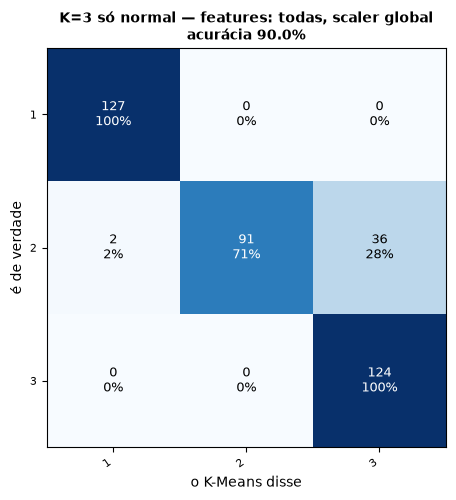

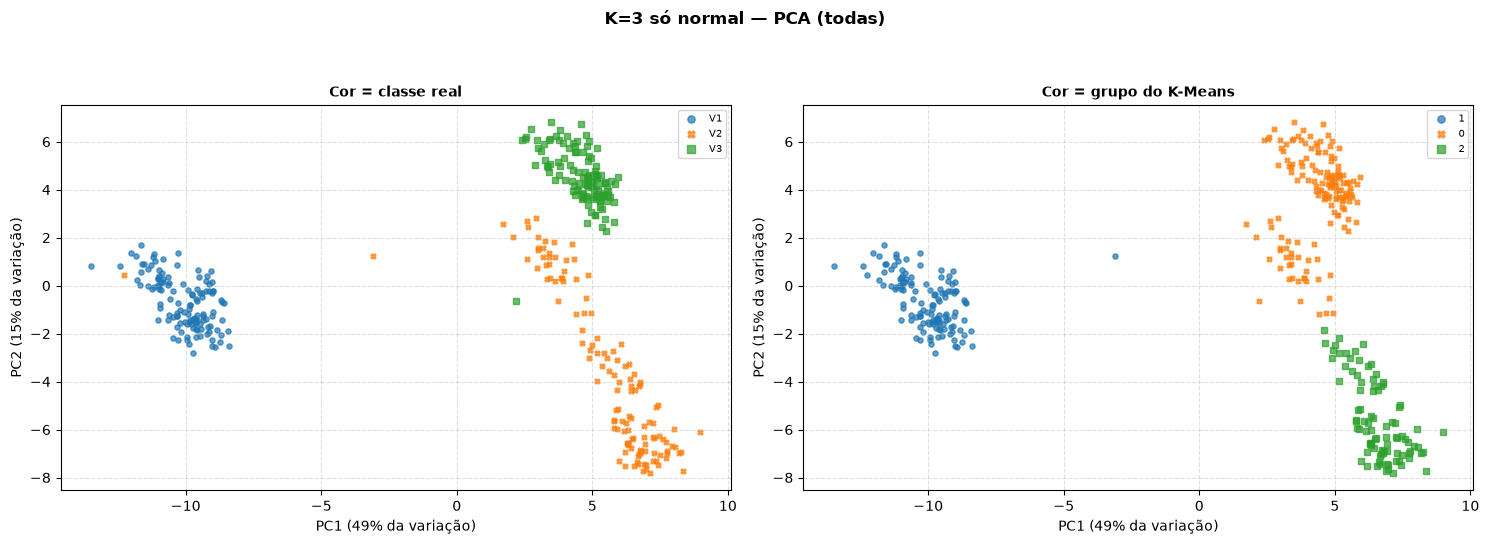

Onde ficaram os erros (por terço da gravação):


terço,1º terço,2º terço,3º terço,total de erros,janelas
base,,,,,
ventilador_normal_vel_2,37,1,0,38,129


In [18]:
so_normal = (gabarito["binario"] == NOME_NORMAL).to_numpy()
classes_velocidade = list(velocidades)

tabela_k3_normal, resultados_k3_normal = comparar_conjuntos(
    features, gabarito, so_normal, len(velocidades), "global", "velocidade", classes_velocidade)
registrar("K=3 só normal (velocidades)", "global", tabela_k3_normal)
display(tabela_k3_normal.round(2))

principal = resultados_k3_normal[CONJUNTO_PRINCIPAL]
plotar_matriz_de_confusao(principal["reais"], principal["previstos"], classes_velocidade,
                          f"K=3 só normal — features: {CONJUNTO_PRINCIPAL}, scaler global")
plotar_pca(principal["padronizada"], [f"V{v}" for v in principal["reais"]], principal["clusters"],
           f"K=3 só normal — PCA ({CONJUNTO_PRINCIPAL})")

print("Onde ficaram os erros (por terço da gravação):")
display(erros_por_terco(principal))

### Conclusões do Passo 6 (nesta execução)

* **Vel 1 e Vel 3:** 100% das janelas normais no grupo certo.
* **Vel 2:** só 71%. Das 129 janelas, **36 foram para o grupo da Vel 3** e 2 para o da Vel 1.
* **Onde estão os erros:** 37 dos 38 estão no **1º terço da gravação** do normal V2, ou seja, nos primeiros cerca de 3 minutos (janelas 0 a 48). **É o aquecimento:** com o motor frio, a Vel 2 vibra de um jeito diferente do resto da sua própria gravação, a ponto de o K-Means achá-la mais parecida com a Vel 3.
* **Com as features de tempo ou de rotação, acerta 99,2%.** O erro vem das **FFT**, que reagem mais à mudança da partida a frio. A rotação (`f1x_hz`) separa bem as velocidades: 12,4 Hz, 18,6 Hz e 22,6 Hz.
* **Consequência para a arquitetura "um modelo chama o outro":** dá para descobrir a velocidade sem rótulo, desde que o primeiro modelo use **features de rotação ou de tempo**. Usando todas as features, a partida a frio da Vel 2 pode ser encaixada na velocidade errada.

## Passo 7 — K=3 em cada falha: as velocidades continuam aparecendo?

**O que buscamos:** o mesmo teste do Passo 6, agora só com as janelas de **uma falha por vez**. A falha muda a vibração. Será que ela muda tanto que as velocidades se misturam?

**Por que uma falha por vez:** se juntássemos as três falhas, o K-Means poderia separar **falhas** em vez de velocidades (por exemplo, "fita" contra "papel e porca"), e não saberíamos se a velocidade ainda aparece. Rodamos cada falha sozinha e, por último, **as três juntas**, para ver o que muda.

**Scaler:** global, pelo mesmo motivo do Passo 6.

**Como ler:** uma matriz por falha. Diagonal cheia = as três velocidades daquela falha foram separadas sem rótulo. Na tabela, a linha "todas as falhas juntas" mostra se a mistura atrapalha.

acurácia (%)   ARI  recall 1 (%)  \
janelas usadas         features                                     
fita_1g                tempo            98.68  0.96        100.00   
                       FFT              98.15  0.94        100.00   
                       rotação          98.68  0.96        100.00   
                       todas            98.41  0.95        100.00   
papel                  tempo            86.81  0.64         84.80   
                       FFT              82.06  0.60        100.00   
                       rotação          94.72  0.85        100.00   
                       todas            82.59  0.60        100.00   
porca_frouxa           tempo            78.53  0.45        100.00   
                       FFT              92.67  0.80        100.00   
                       rotação          99.74  0.99        100.00   
                       todas            92.93  0.81        100.00   
todas as falhas juntas tempo            56.10  0.11         70.40   
                       FFT              65.67  0.25         99.47   
                       rotação          65.32  0.43         97.07   
                       todas            65.94  0.25        100.00   

                                 precisão 1 (%)  recall 2 (%)  precisão 2 (%)  \
janelas usadas         features                                                 
fita_1g                tempo              97.62         96.12          100.00   
                       FFT                99.19         96.12           98.41   
                       rotação            96.85         96.90           99.21   
                       todas              97.62         96.12           99.20   
papel                  tempo              86.89         75.40          100.00   
                       FFT                93.28         46.03          100.00   
                       rotação            86.21         84.92          100.00   
                       todas              87.41         47.62          100.00   
porca_frouxa           tempo              60.77         77.17          100.00   
                       FFT                99.22         77.95          100.00   
                       rotação            99.22         99.21          100.00   
                       todas              99.22         78.74          100.00   
todas as falhas juntas tempo              50.38         32.20           98.40   
                       FFT                57.83         32.46           97.64   
                       rotação            92.15         32.46           49.80   
                       todas              56.82         32.46           98.41   

                                 recall 3 (%)  precisão 3 (%)  
janelas usadas         features                                
fita_1g                tempo           100.00           98.44  
                       FFT              98.41           96.88  
                       rotação          99.21          100.00  
                       todas            99.21           98.43  
papel                  tempo           100.00           79.01  
                       FFT             100.00           68.45  
                       rotação          99.22          100.00  
                       todas           100.00           72.73  
porca_frouxa           tempo            58.59          100.00  
                       FFT             100.00           82.58  
                       rotação         100.00          100.00  
                       todas           100.00           83.12  
todas as falhas juntas tempo            65.97           51.43  
                       FFT              65.71           68.39  
                       rotação          67.02           51.72  
                       todas            65.97           71.39

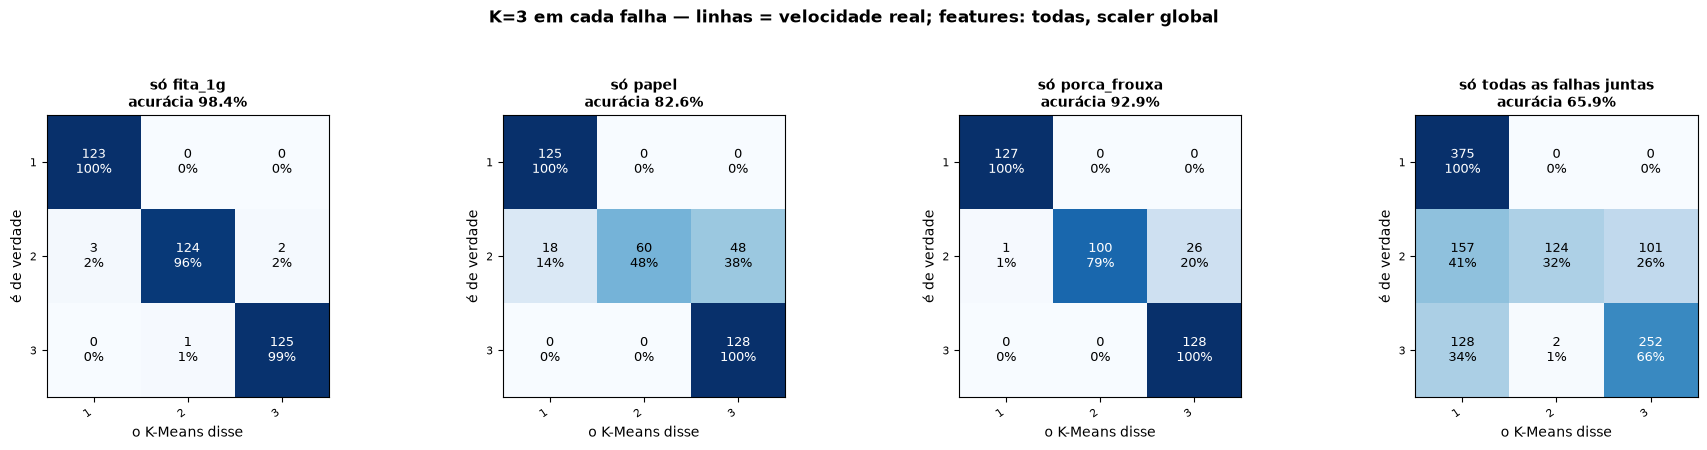

In [19]:
so_anomalia = (gabarito["binario"] == NOME_ANOMALIA).to_numpy()
selecoes_k3 = {falha: (gabarito["condicao"] == falha).to_numpy() for falha in condicoes_comparadas}
selecoes_k3["todas as falhas juntas"] = so_anomalia

tabelas_k3_falha, resultados_k3_falha = {}, {}
for nome, selecao in selecoes_k3.items():
    tabela, resultados = comparar_conjuntos(features, gabarito, selecao, len(velocidades), "global", "velocidade", classes_velocidade)
    registrar(f"K=3 só {nome} (velocidades)", "global", tabela)
    tabelas_k3_falha[nome], resultados_k3_falha[nome] = tabela, resultados
display(pd.concat(tabelas_k3_falha, names=["janelas usadas", "features"]).round(2))

fig, axs = plt.subplots(1, len(selecoes_k3), figsize=(4.6 * len(selecoes_k3), 4.4), squeeze=False)
for ax, nome in zip(axs[0], selecoes_k3):
    r = resultados_k3_falha[nome][CONJUNTO_PRINCIPAL]
    plotar_matriz_de_confusao(r["reais"], r["previstos"], classes_velocidade, f"só {nome}", ax=ax)
fig.suptitle(f"K=3 em cada falha — linhas = velocidade real; features: {CONJUNTO_PRINCIPAL}, scaler global", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

### Conclusões do Passo 7 (nesta execução)

* **Fita:** as três velocidades separadas com cerca de **98%**, com qualquer conjunto de features.
* **Papel e porca:** depende das features.
  * Com **rotação**, acerta **94,7%** no papel e **99,7%** na porca.
  * Com **todas** as features, o papel cai para **82,6%**: só 48% da Vel 2 fica no grupo certo, e o resto vai para a Vel 3. A porca cai para **92,9%**.
  * Ou seja, as FFT do papel e da porca misturam a Vel 2 com a Vel 3. As features de rotação continuam separando.
* **Todas as falhas juntas:** a acurácia cai para **cerca de 66%**, e só cerca de 32% da Vel 2 fica no grupo certo. Com três falhas de forças diferentes, os grupos passam a misturar **velocidade e tipo de falha**. Por exemplo, a fita V2 (que vibra muito) fica parecida com a fita V3.
* **Conclusão:** o primeiro modelo, o que descobre a velocidade, deve usar as **features de rotação**. Elas medem a velocidade diretamente e quase não mudam com a falha.

## Passo 8 — K=2 global: separa normal de anomalia sem saber a velocidade?

**O que buscamos:** juntar **todas as janelas** (3 velocidades, normal e falha) e pedir 2 grupos. Seria o detector mais simples possível: nem precisa saber a velocidade.

**Scaler: global** (não há velocidade conhecida nesse cenário).

**O que esperamos:** é o cenário em que o scaler global "esconde as magnitudes" (Passo 4). Nos dados antigos, ele detectou 100% da fita na Vel 2 e quase toda na Vel 3, mas **0% na Vel 1**. Nos dados novos há mais um risco: com três falhas de forças diferentes, os dois grupos podem virar "falha forte" (fita das Vel 2 e 3, por exemplo) contra "todo o resto", com o normal, a porca e o papel juntos.

**Como ler:** além da matriz geral, olhe a tabela **"% chamada de anomalia"**, por condição e velocidade. Na linha do normal, o número é o **falso alarme**. Nas linhas das falhas, é o **recall daquela falha**. Uma acurácia geral alta pode esconder uma falha ou uma velocidade inteira não detectada.

In [20]:
def recall_por_velocidade(resultado, velocidades):
    """Recall do normal e da anomalia separado por velocidade, a partir de um resultado de K=2."""
    linhas = []
    for velocidade in velocidades:
        sel = (resultado["rotulos"]["velocidade"] == velocidade).to_numpy()
        reais, previstos = resultado["reais"][sel], resultado["previstos"][sel]
        linha = {"velocidade": velocidade}
        for classe in (NOME_NORMAL, NOME_ANOMALIA):
            e_da_classe = reais == classe
            linha[f"recall {classe} (%)"] = 100 * (previstos[e_da_classe] == classe).mean() if e_da_classe.any() else np.nan
        linha["falso alarme (%)"] = 100 - linha[f"recall {NOME_NORMAL} (%)"]
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index("velocidade")
def taxa_de_anomalia_por_condicao(rotulos, previstos):
    """% das janelas que o K-Means chamou de anomalia, por condição (linhas) e velocidade (colunas).

    Na linha do normal, esse número é o falso alarme. Nas linhas das falhas, é o recall daquela falha.
    """
    tabela = pd.DataFrame({"condicao": rotulos["condicao"].to_numpy(), "velocidade": rotulos["velocidade"].to_numpy(),
                           "disse anomalia": np.asarray(previstos) == NOME_ANOMALIA})
    resultado = 100 * tabela.pivot_table(index="condicao", columns="velocidade", values="disse anomalia", aggfunc="mean")
    resultado.columns = [f"Vel {v}" for v in resultado.columns]
    return resultado.reindex([c for c in ORDEM_CONDICOES if c in resultado.index])

,acurácia (%),ARI,recall normal (%),precisão normal (%),recall anomalia (%),precisão anomalia (%)
tempo,58.13,-0.00,100.00,37.40,44.16,100.00
FFT,57.08,-0.01,100.00,36.82,42.76,100.00
rotação,55.56,-0.01,34.74,23.61,62.51,74.17
todas,56.16,-0.02,100.00,36.33,41.53,100.00


% chamada de anomalia por condição e velocidade (todas) — linha do normal = falso alarme:


,Vel 1,Vel 2,Vel 3
condicao,,,
normal,0.0,0.0,0.0
fita_1g,0.0,96.9,100.0
papel,0.0,74.6,100.0
porca_frouxa,0.0,0.0,0.0


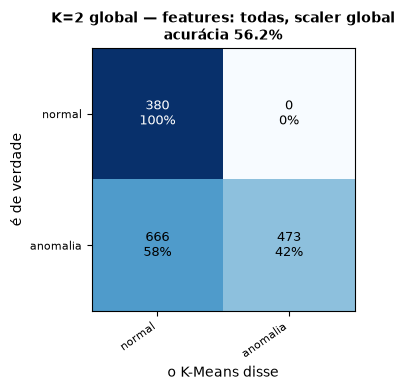

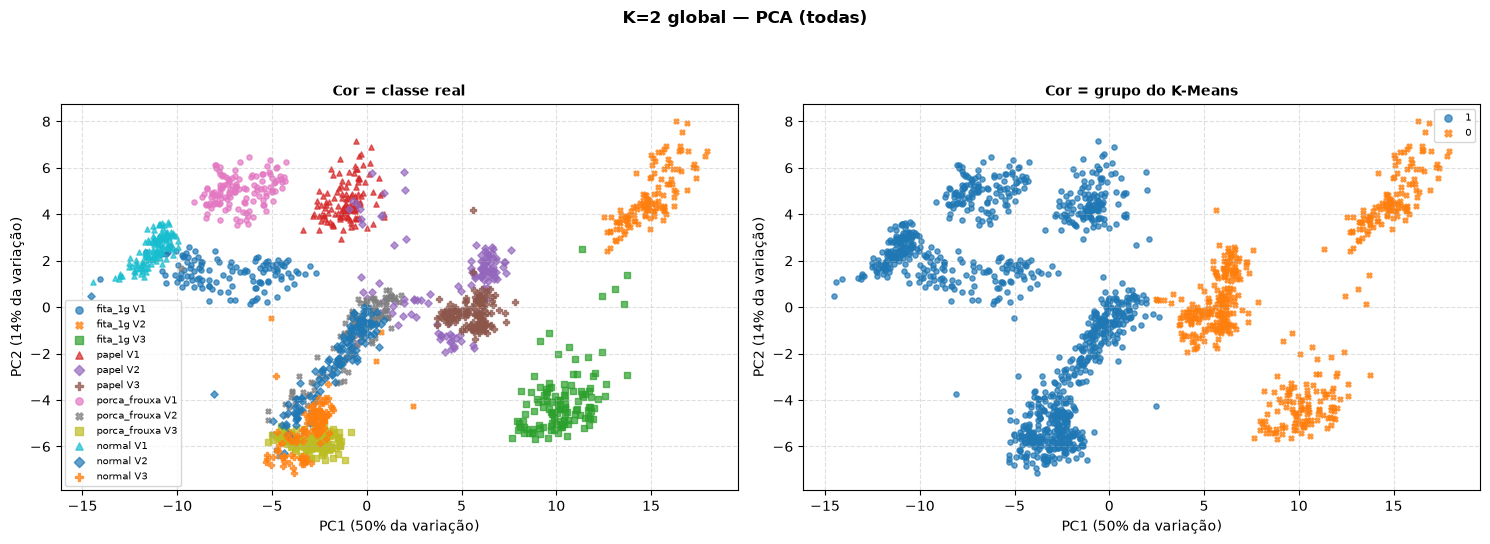

In [21]:
todas_as_janelas = np.ones(len(features), dtype=bool)
classes_binarias = [NOME_NORMAL, NOME_ANOMALIA]

tabela_k2_global, resultados_k2_global = comparar_conjuntos(
    features, gabarito, todas_as_janelas, 2, "global", "binario", classes_binarias)
registrar("K=2 global (normal x anomalia)", "global", tabela_k2_global, f"recall {NOME_ANOMALIA} (%)")
display(tabela_k2_global.round(2))

principal = resultados_k2_global[CONJUNTO_PRINCIPAL]
print(f"% chamada de anomalia por condição e velocidade ({CONJUNTO_PRINCIPAL}) — linha do normal = falso alarme:")
display(taxa_de_anomalia_por_condicao(principal["rotulos"], principal["previstos"]).round(1))
plotar_matriz_de_confusao(principal["reais"], principal["previstos"], classes_binarias,
                          f"K=2 global — features: {CONJUNTO_PRINCIPAL}, scaler global")
plotar_pca(principal["padronizada"], principal["rotulos"]["classe"], principal["clusters"],
           f"K=2 global — PCA ({CONJUNTO_PRINCIPAL})")

### Conclusões do Passo 8 (nesta execução)

* **Acurácia cerca de 56% e ARI perto de 0:** o K=2 global **não funciona como detector**.
* **O que ele separou (tabela "% chamada de anomalia"):**
  * um grupo com a **fita das Vel 2 e 3** (97% e 100%) e o **papel das Vel 2 e 3** (75% e 100%);
  * o outro grupo com **todo o resto**: o normal das três velocidades, **todas as falhas da Vel 1** e a **porca em todas as velocidades** (0%).
* **Falso alarme 0%, mas recall de só 41,5%.** É o problema previsto no Passo 4: a régua global é dominada pelas falhas fortes das velocidades altas, e as fracas (Vel 1 e porca) se escondem no normal.
* **Igual aos dados antigos:** a falha da Vel 1 não é detectada sem saber a velocidade.

## Passo 9 — K=2 dentro de cada velocidade, com scaler local: o teste principal

**O que buscamos:** a detecção de falha na forma em que ela seria usada: **sabendo a velocidade**, separar normal de anomalia. Para cada velocidade, separadamente:

1. pegamos só as janelas daquela velocidade;
2. aplicamos o log;
3. padronizamos com o **scaler local**;
4. rodamos K=2 e comparamos com o gabarito.

**Dois scalers, lado a lado (a diferença está explicada no Passo 4):**

* **(b) principal:** média e desvio **só do normal** daquela velocidade. Mede "o quanto a janela foge do normal".
* **(a) comparação:** média e desvio de **todas as janelas** daquela velocidade. É o que os notebooks antigos faziam.

**Com três falhas, fazemos o teste de dois jeitos:**

| | **9.1 — Normal × cada falha** | **9.2 — Normal × todas as falhas juntas** |
| --- | --- | --- |
| Janelas usadas | normal + **uma** falha, na mesma velocidade | normal + **as três** falhas, na mesma velocidade |
| Proporção | cerca de 1 normal para 1 falha | cerca de 1 normal para 3 falhas |
| Pergunta | **esta** falha se separa do normal sozinha? | um detector que não sabe qual falha vai aparecer separa o normal de tudo o resto? |
| Risco | nenhum especial | o K-Means pode dividir em "fita" × "resto" e jogar a porca junto com o normal |

O **9.2** é o mais parecido com o uso real. O **9.1** mostra **qual falha** é difícil.

### 9.1 — Normal × cada falha

**Como ler:** a tabela traz cada falha, velocidade, scaler e conjunto de features. As matrizes mostram o `CONJUNTO_PRINCIPAL` com o scaler (b): uma linha por falha e uma coluna por velocidade. O mapa de cores no fim resume o **recall da falha** e o **falso alarme** de todas as combinações.

In [22]:
def k2_por_velocidade(features, gabarito, tipo_scaler, conjuntos=CONJUNTOS):
    """K=2 em cada velocidade separadamente. Devolve (tabela de métricas, resultados[(velocidade, conjunto)])."""
    linhas, resultados = [], {}
    for velocidade in velocidades:
        selecao = (gabarito["velocidade"] == velocidade).to_numpy()
        for nome, colunas in conjuntos.items():
            resultado = rodar_experimento(features, gabarito, selecao, colunas, 2, tipo_scaler, "binario", classes_binarias)
            resultados[(velocidade, nome)] = resultado
            metricas = resultado["metricas"]
            linhas.append({"velocidade": velocidade, "features": nome, "scaler": tipo_scaler,
                           "acurácia (%)": metricas["acurácia (%)"], "ARI": metricas["ARI"],
                           f"recall {NOME_ANOMALIA} (%)": metricas[f"recall {NOME_ANOMALIA} (%)"],
                           "falso alarme (%)": 100 - metricas[f"recall {NOME_NORMAL} (%)"]})
    return pd.DataFrame(linhas), resultados


def juntar_velocidades(resultados, conjunto):
    """Junta os resultados das velocidades num só (para a matriz geral e o resumo)."""
    partes = [resultados[(v, conjunto)] for v in velocidades]
    reais = np.concatenate([p["reais"] for p in partes])
    previstos = np.concatenate([p["previstos"] for p in partes])
    clusters_unicos = np.concatenate([np.char.add(f"V{v}-", p["clusters"].astype(str)) for v, p in zip(velocidades, partes)])
    return reais, previstos, clusters_unicos

In [23]:
def k2_por_falha(features, gabarito, tipo_scaler, conjuntos=CONJUNTOS):
    """K=2 em cada velocidade, usando só o normal e UMA falha por vez. Devolve (tabela, resultados[(falha, velocidade, conjunto)])."""
    tabelas, resultados = [], {}
    for falha in condicoes_comparadas:
        selecao = gabarito["condicao"].isin([NOME_NORMAL, falha]).to_numpy()
        tabela, res = k2_por_velocidade(features.loc[selecao], gabarito.loc[selecao], tipo_scaler, conjuntos)
        tabela.insert(0, "falha", falha)
        tabelas.append(tabela)
        resultados.update({(falha, v, c): r for (v, c), r in res.items()})
    return pd.concat(tabelas, ignore_index=True), resultados


def plotar_mapa_k2_por_falha(tabela_por_falha):
    """Dois mapas (recall da falha e falso alarme): linhas = scaler e features, colunas = falha e velocidade."""
    grade_base = tabela_por_falha.set_index(["scaler", "features", "falha", "velocidade"])
    linhas = grade_base.index.droplevel(["falha", "velocidade"]).unique()
    fig, axs = plt.subplots(2, 1, figsize=(16, 0.9 * len(linhas) + 6))
    for ax, medida, mapa_cor, titulo in ((axs[0], f"recall {NOME_ANOMALIA} (%)", "Greens", "Recall da falha (%) — maior é melhor"),
                                          (axs[1], "falso alarme (%)", "Reds", "Falso alarme (%) — menor é melhor")):
        grade = grade_base[medida].unstack(["falha", "velocidade"]).reindex(linhas)
        ax.imshow(grade.to_numpy(dtype=float), cmap=mapa_cor, vmin=0, vmax=100, aspect="auto")
        for i in range(grade.shape[0]):
            for j in range(grade.shape[1]):
                valor = grade.iat[i, j]
                ax.text(j, i, f"{valor:.0f}", ha="center", va="center", fontsize=9, color="white" if valor > 60 else "black")
        ax.set_xticks(range(grade.shape[1]))
        ax.set_xticklabels([f"{f}\nVel {v}" for f, v in grade.columns], fontsize=8)
        ax.set_yticks(range(grade.shape[0]))
        ax.set_yticklabels([f"{s} | {f}" for s, f in grade.index], fontsize=8)
        for j in range(len(velocidades), grade.shape[1], len(velocidades)):
            ax.axvline(j - 0.5, color="black", linewidth=2)
        ax.grid(False)
        ax.set_title(titulo, fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [24]:
tabela_k2_falha_b, resultados_k2_falha_b = k2_por_falha(features, gabarito, "local_b")
tabela_k2_falha_a, resultados_k2_falha_a = k2_por_falha(features, gabarito, "local_a")
tabela_k2_falha = pd.concat([tabela_k2_falha_b, tabela_k2_falha_a])

colunas_mostradas = ["acurácia (%)", f"recall {NOME_ANOMALIA} (%)", "falso alarme (%)", "ARI"]
print(f"Scaler (b), features: {CONJUNTO_PRINCIPAL}")
display(tabela_k2_falha_b[tabela_k2_falha_b["features"] == CONJUNTO_PRINCIPAL]
        .set_index(["falha", "velocidade"])[colunas_mostradas].round(2))

for tipo, tabela in (("local_b", tabela_k2_falha_b), ("local_a", tabela_k2_falha_a)):
    for (falha, conjunto), parte in tabela.groupby(["falha", "features"]):
        RESUMO.append({"experimento": f"K=2 por velocidade (normal x {falha})", "scaler": tipo, "features": conjunto,
                       "acurácia (%)": parte["acurácia (%)"].mean(), "ARI": parte["ARI"].mean(),
                       "destaque": f"recall {falha} mín. entre velocidades: {parte[f'recall {NOME_ANOMALIA} (%)'].min():.1f}"})

Scaler (b), features: todas


acurácia (%)  recall anomalia (%)  falso alarme (%)  \
falha        velocidade                                                        
fita_1g      1                  80.40                60.16              0.00   
             2                  98.06                96.12              0.00   
             3                 100.00               100.00              0.00   
papel        1                 100.00               100.00              0.00   
             2                 100.00               100.00              0.00   
             3                 100.00               100.00              0.00   
porca_frouxa 1                 100.00               100.00              0.00   
             2                  55.86                63.78             51.94   
             3                 100.00               100.00              0.00   

                          ARI  
falha        velocidade        
fita_1g      1           0.37  
             2           0.92  
             3           1.00  
papel        1           1.00  
             2           1.00  
             3           1.00  
porca_frouxa 1           1.00  
             2           0.01  
             3           1.00

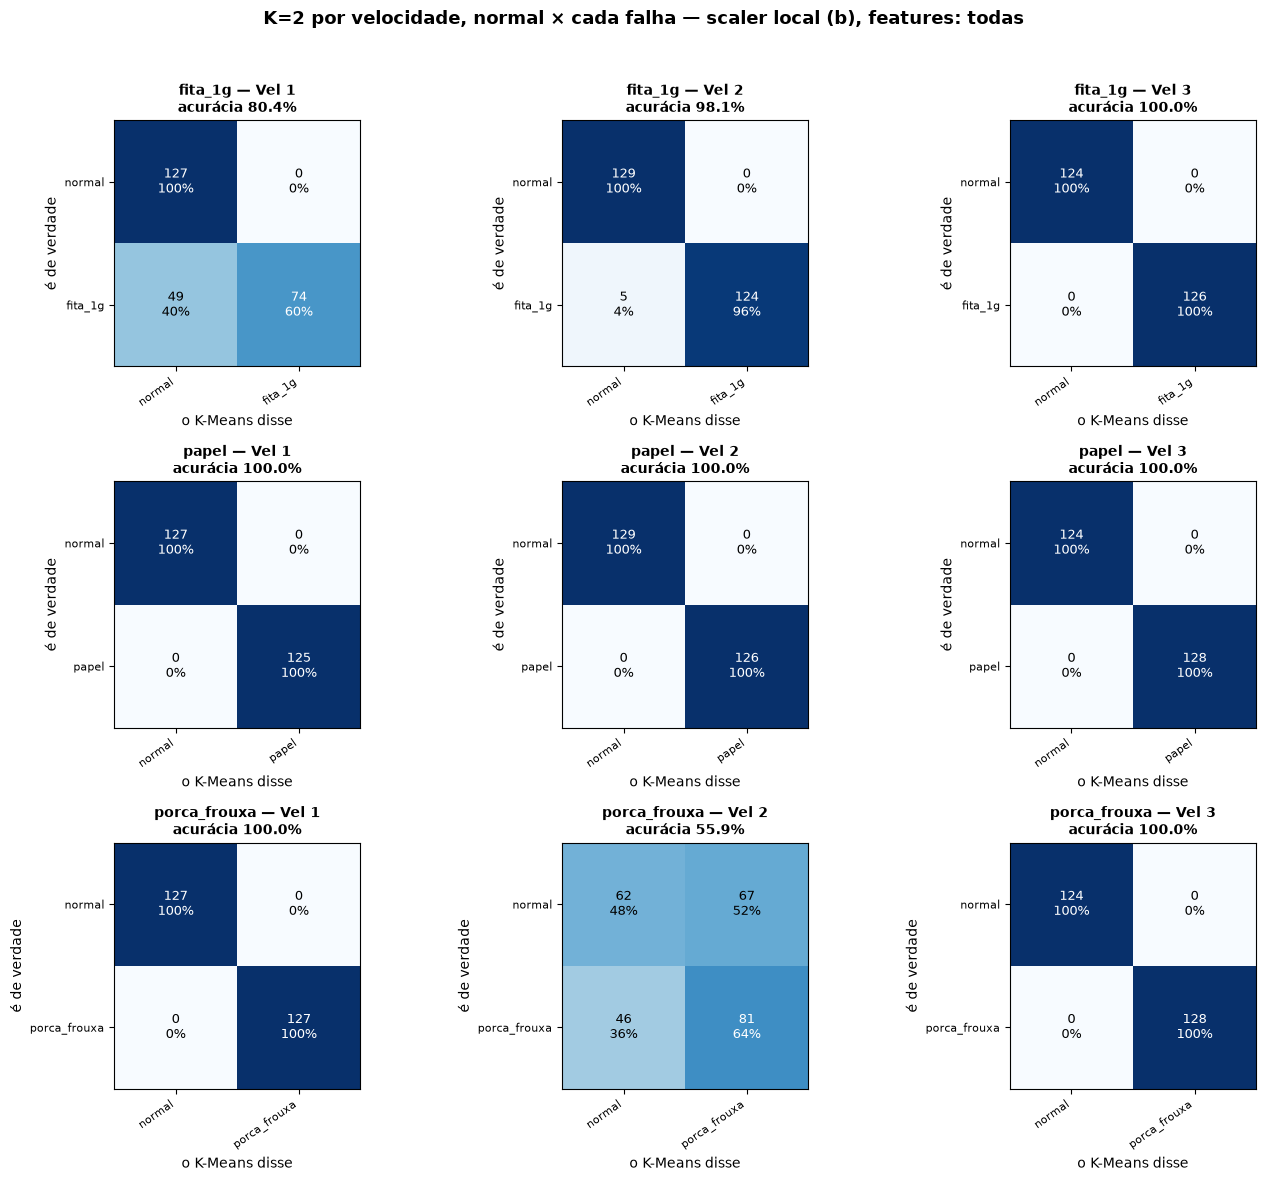

In [25]:
fig, axs = plt.subplots(len(condicoes_comparadas), len(velocidades),
                        figsize=(4.6 * len(velocidades), 4.0 * len(condicoes_comparadas)), squeeze=False)
for linha, falha in enumerate(condicoes_comparadas):
    for coluna, velocidade in enumerate(velocidades):
        r = resultados_k2_falha_b[(falha, velocidade, CONJUNTO_PRINCIPAL)]
        reais = np.where(r["reais"] == NOME_ANOMALIA, falha, NOME_NORMAL)
        previstos = np.where(r["previstos"] == NOME_ANOMALIA, falha, NOME_NORMAL)
        plotar_matriz_de_confusao(reais, previstos, [NOME_NORMAL, falha], f"{falha} — Vel {velocidade}", ax=axs[linha, coluna])
fig.suptitle(f"K=2 por velocidade, normal × cada falha — scaler local (b), features: {CONJUNTO_PRINCIPAL}", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

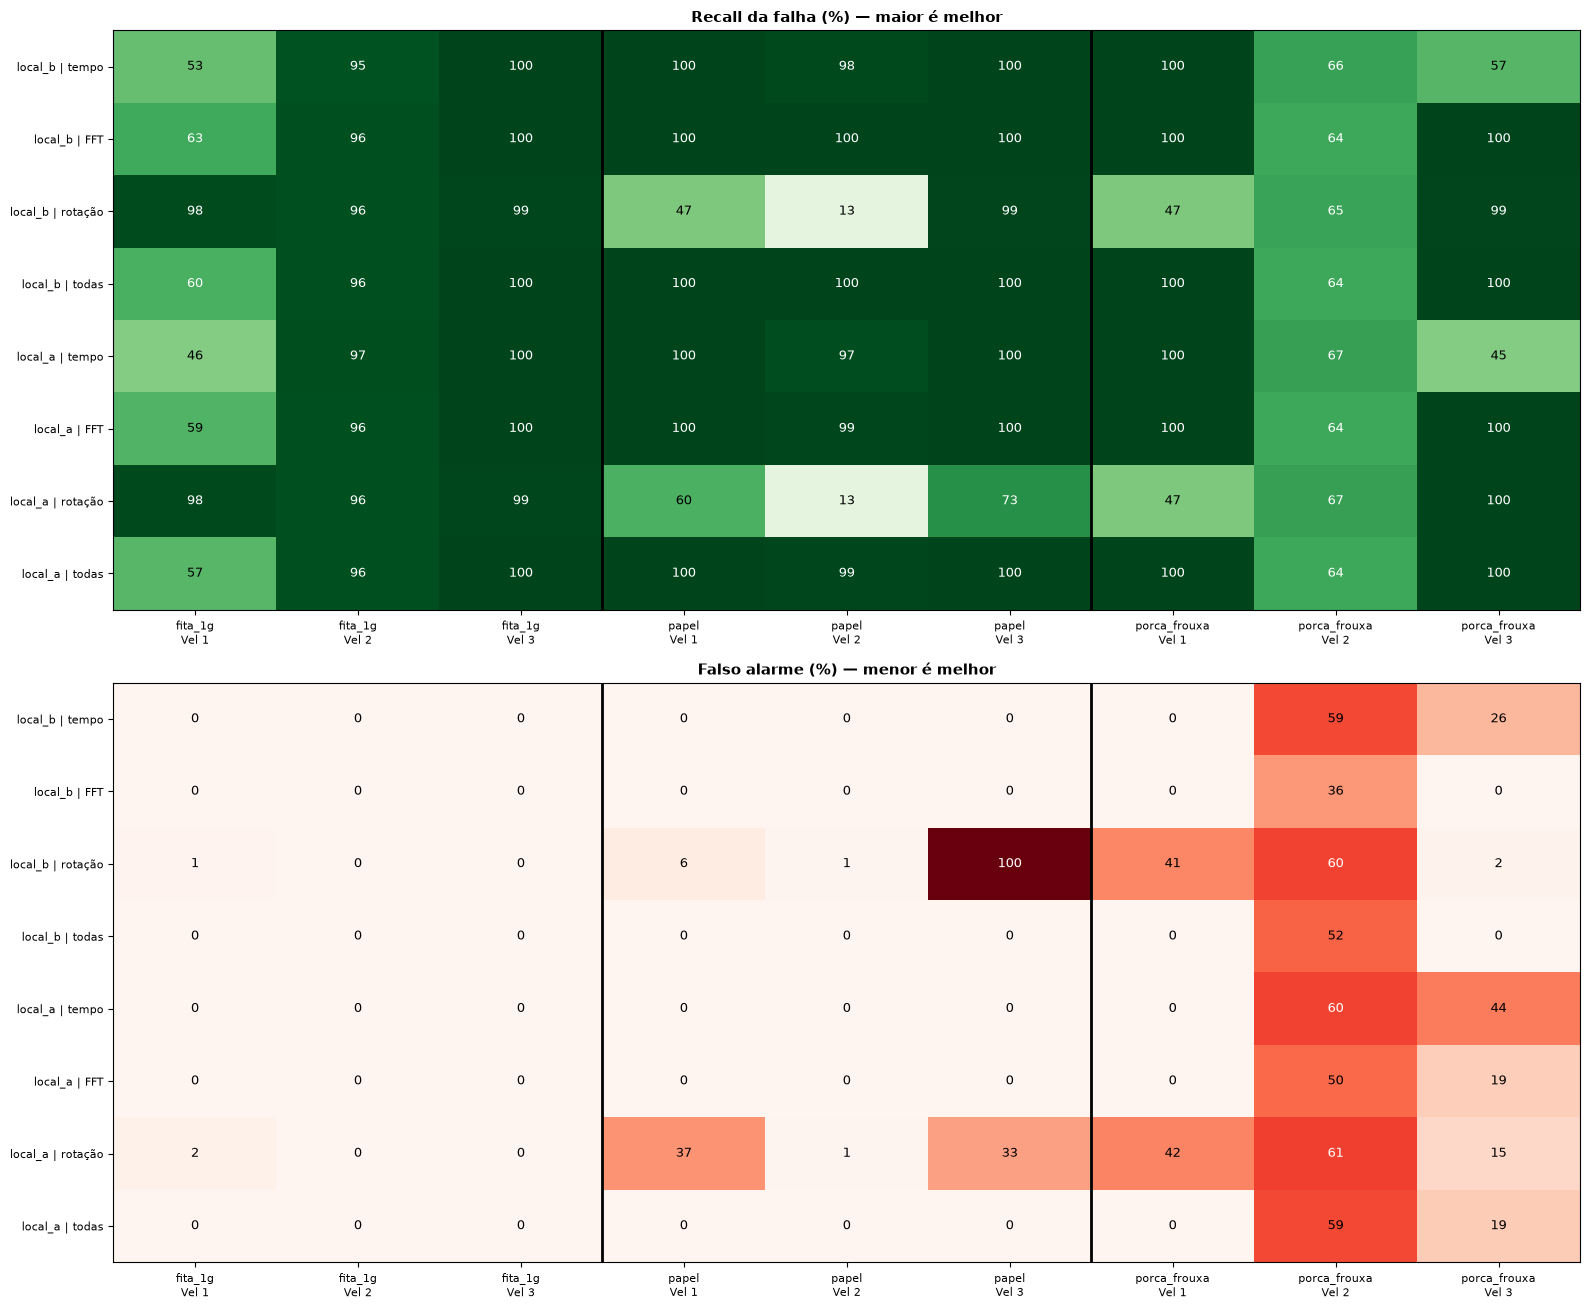

In [26]:
plotar_mapa_k2_por_falha(tabela_k2_falha)

### 9.2 — Normal × todas as falhas juntas

**O que buscamos:** agora, em cada velocidade, entram o normal e **as três falhas ao mesmo tempo**, e pedimos K=2. É o detector "de verdade": ele não sabe qual falha vai aparecer.

**Como ler:**

* **A primeira tabela** traz cada velocidade, scaler e conjunto de features. O recall da anomalia junta as três falhas.
* **A tabela "% chamada de anomalia"** abre esse recall por falha. Na linha do **normal**, o número é o **falso alarme**. Nas linhas das **falhas**, é o **recall daquela falha**. É aqui que aparece se alguma falha "se esconde" no grupo do normal.
* **As matrizes** mostram o scaler (b) com o `CONJUNTO_PRINCIPAL`, uma por velocidade.
* **O mapa de cores** resume recall e falso alarme de todas as combinações.

In [27]:
tabela_k2_local_b, resultados_k2_local_b = k2_por_velocidade(features, gabarito, "local_b")
tabela_k2_local_a, resultados_k2_local_a = k2_por_velocidade(features, gabarito, "local_a")
tabela_k2_local = pd.concat([tabela_k2_local_b, tabela_k2_local_a]).set_index(["scaler", "velocidade", "features"])
display(tabela_k2_local.round(2))

for tipo, resultados in (("local_b", resultados_k2_local_b), ("local_a", resultados_k2_local_a)):
    for conjunto in CONJUNTOS:
        reais, previstos, clusters_unicos = juntar_velocidades(resultados, conjunto)
        RESUMO.append({"experimento": "K=2 por velocidade (normal x todas as falhas)", "scaler": tipo, "features": conjunto,
                       "acurácia (%)": 100 * (reais == previstos).mean(),
                       "ARI": np.mean([resultados[(v, conjunto)]["metricas"]["ARI"] for v in velocidades]),
                       "destaque": f"recall {NOME_ANOMALIA} mín. entre velocidades: "
                                   f"{min(resultados[(v, conjunto)]['metricas'][f'recall {NOME_ANOMALIA} (%)'] for v in velocidades):.1f}"})

acurácia (%)   ARI  recall anomalia (%)  \
scaler  velocidade features                                            
local_b 1          tempo            50.20 -0.07                33.33   
                   FFT              75.50  0.26                67.20   
                   rotação          59.76  0.02                47.73   
                   todas            50.20 -0.07                33.33   
        2          tempo            51.27 -0.07                68.59   
                   FFT              63.21  0.06                50.79   
                   rotação          50.49 -0.07                67.54   
                   todas            50.49 -0.07                67.54   
        3          tempo            74.70  0.24                66.49   
                   FFT              74.70  0.24                66.49   
                   rotação          50.79 -0.07                67.28   
                   todas            74.70  0.24                66.49   
local_a 1          tempo            50.20 -0.07                33.33   
                   FFT              57.97 -0.01                43.73   
                   rotação          58.76  0.01                47.20   
                   todas            50.20 -0.07                33.33   
        2          tempo            50.49 -0.07                67.54   
                   FFT              50.49 -0.07                67.54   
                   rotação          50.49 -0.07                67.54   
                   todas            50.49 -0.07                67.54   
        3          tempo            74.70  0.24                66.49   
                   FFT              74.70  0.24                66.49   
                   rotação          50.79 -0.07                67.28   
                   todas            74.70  0.24                66.49   

                             falso alarme (%)  
scaler  velocidade features                    
local_b 1          tempo                 0.00  
                   FFT                   0.00  
                   rotação               4.72  
                   todas                 0.00  
        2          tempo               100.00  
                   FFT                   0.00  
                   rotação             100.00  
                   todas               100.00  
        3          tempo                 0.00  
                   FFT                   0.00  
                   rotação             100.00  
                   todas                 0.00  
local_a 1          tempo                 0.00  
                   FFT                   0.00  
                   rotação               7.09  
                   todas                 0.00  
        2          tempo               100.00  
                   FFT                 100.00  
                   rotação             100.00  
                   todas               100.00  
        3          tempo                 0.00  
                   FFT                   0.00  
                   rotação             100.00  
                   todas                 0.00

In [28]:
print(f"% chamada de anomalia por condição — K=2 por velocidade com todas as falhas, scaler (b), features {CONJUNTO_PRINCIPAL}")
print("(linha do normal = falso alarme; linhas das falhas = recall daquela falha)")
reais_92, previstos_92, _ = juntar_velocidades(resultados_k2_local_b, CONJUNTO_PRINCIPAL)
rotulos_92 = pd.concat([resultados_k2_local_b[(v, CONJUNTO_PRINCIPAL)]["rotulos"] for v in velocidades])
display(taxa_de_anomalia_por_condicao(rotulos_92, previstos_92).round(1))

% chamada de anomalia por condição — K=2 por velocidade com todas as falhas, scaler (b), features todas
(linha do normal = falso alarme; linhas das falhas = recall daquela falha)


,Vel 1,Vel 2,Vel 3
condicao,,,
normal,0.0,100.0,0.0
fita_1g,0.0,3.9,100.0
papel,100.0,100.0,100.0
porca_frouxa,0.0,100.0,0.0


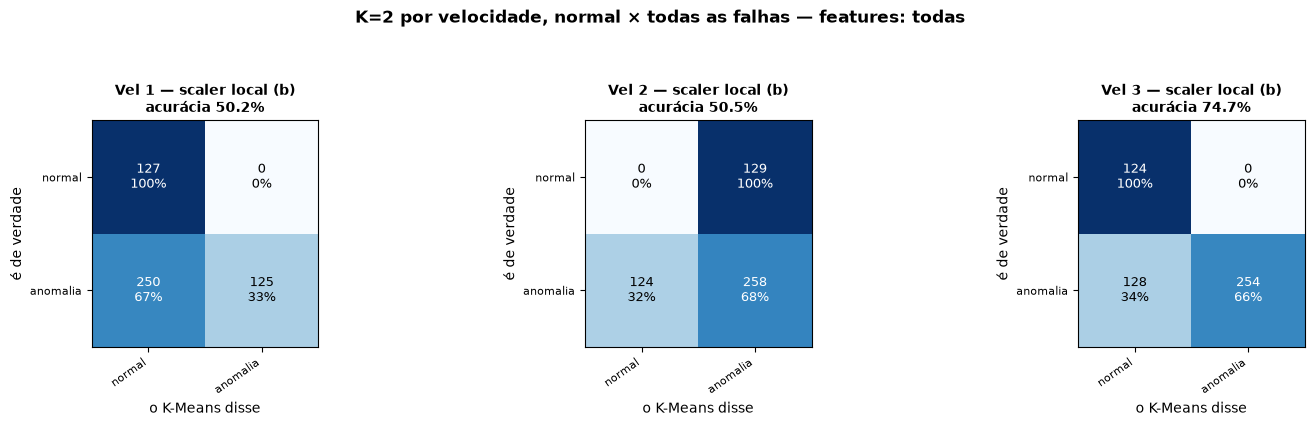

In [29]:
fig, axs = plt.subplots(1, len(velocidades), figsize=(5 * len(velocidades), 4.3))
for ax, velocidade in zip(np.atleast_1d(axs), velocidades):
    r = resultados_k2_local_b[(velocidade, CONJUNTO_PRINCIPAL)]
    plotar_matriz_de_confusao(r["reais"], r["previstos"], classes_binarias, f"Vel {velocidade} — scaler local (b)", ax=ax)
fig.suptitle(f"K=2 por velocidade, normal × todas as falhas — features: {CONJUNTO_PRINCIPAL}", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [30]:
def plotar_mapa_k2_local(tabela_local):
    """Dois mapas de cores (recall da anomalia e falso alarme): linhas = scaler e features, colunas = velocidade."""
    fig, axs = plt.subplots(1, 2, figsize=(14, 0.45 * len(tabela_local.index.droplevel("velocidade").unique()) + 2.5))
    for ax, medida, mapa_cor, titulo in ((axs[0], f"recall {NOME_ANOMALIA} (%)", "Greens", "Recall da anomalia (%) — maior é melhor"),
                                          (axs[1], "falso alarme (%)", "Reds", "Falso alarme (%) — menor é melhor")):
        grade = tabela_local[medida].unstack("velocidade")
        ax.imshow(grade.to_numpy(dtype=float), cmap=mapa_cor, vmin=0, vmax=100, aspect="auto")
        for i in range(grade.shape[0]):
            for j in range(grade.shape[1]):
                valor = grade.iat[i, j]
                ax.text(j, i, f"{valor:.0f}", ha="center", va="center", fontsize=9, color="white" if valor > 60 else "black")
        ax.set_xticks(range(grade.shape[1]))
        ax.set_xticklabels([f"Vel {v}" for v in grade.columns])
        ax.set_yticks(range(grade.shape[0]))
        ax.set_yticklabels([f"{s} | {f}" for s, f in grade.index], fontsize=8)
        ax.grid(False)
        ax.set_title(titulo, fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()

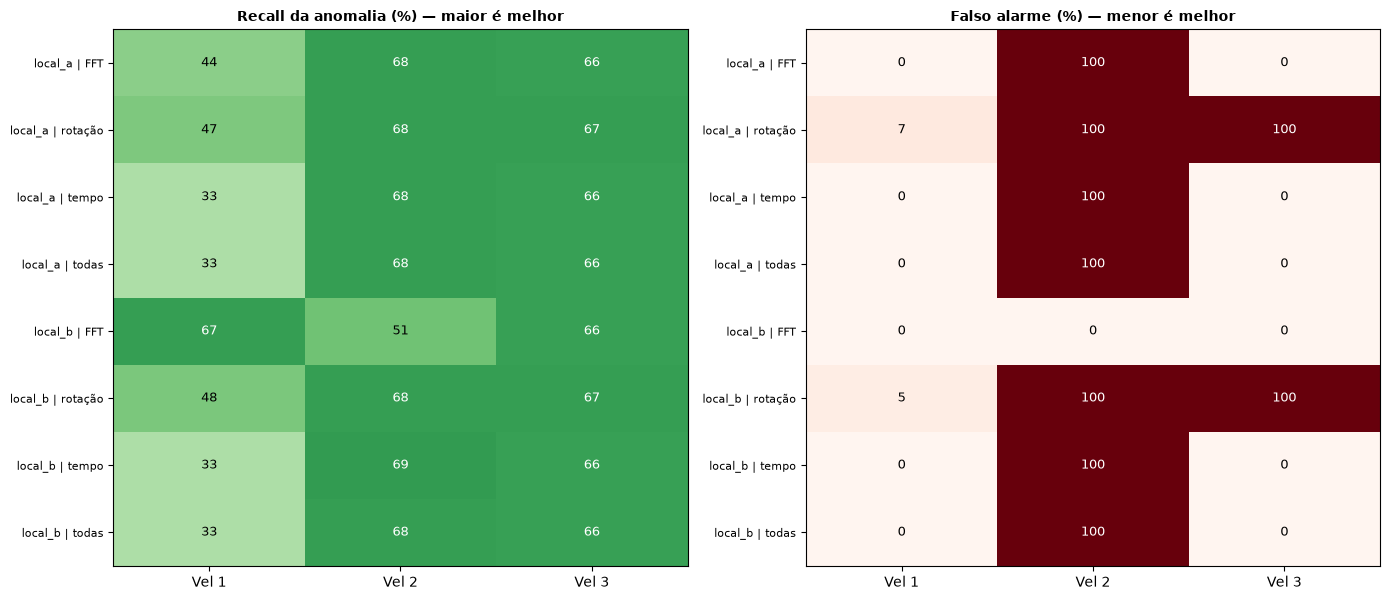

In [31]:
plotar_mapa_k2_local(tabela_k2_local)

### Conclusões do Passo 9 (nesta execução)

**9.1 — Normal × cada falha (scaler b, todas as features):**

| | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| Fita (recall / falso alarme) | **60%** / 0% | 96% / 0% | 100% / 0% |
| Papel | 100% / 0% | 100% / 0% | 100% / 0% |
| Porca | 100% / 0% | **64% / 52%** | 100% / 0% |

* **Papel:** separado perfeitamente nas três velocidades.
* **Porca:** perfeita nas Vel 1 e 3. Na **Vel 2 o K=2 não separou a porca** (ARI 0,01). O erro em 12.1 mostra o que ele fez: dividiu o **começo** das duas gravações (normal e porca) do **fim** delas. Ou seja, separou **o aquecimento**, e não a falha. Bate com o Notebook 02, em que a porca V2 teve só 1 feature acima do teto do controle.
* **Fita V1:** 40% das janelas da fita foram chamadas de normais, e **41 dos 49 erros estão no 1º terço da gravação**. Nos primeiros cerca de 3 minutos, a fita V1 ainda parece normal. Hipótese: com o motor frio, a rotação é menor, e a força do desbalanceamento cresce com o quadrado da rotação. A confirmar.
* **Scaler (a) × (b):** nos pares fáceis, os dois empatam. Nos difíceis, o **(b) é melhor**: na porca V3 com todas as features, o (b) tem 0% de falso alarme e o (a) tem 19%.
* **Conjunto de features (mapa de cores):**
  * **FFT** e **todas** são os melhores no geral.
  * **Tempo** falha na porca V3 (57% de recall).
  * **Rotação** é o pior para o papel e a porca, que quase não mexem nas harmônicas (Notebook 02). Mas é o **melhor para a fita V1: 98% de recall**, contra 60% com todas as features. A assinatura da fita é a 1X (desbalanceamento), e com todas as features ela fica "diluída" entre as outras 99. É um bom argumento para que o classificador do Notebook 05 possa dar pesos diferentes às features, coisa que o K-Means não faz.

**9.2 — Normal × todas as falhas juntas:**
* **O K=2 não funciona como detector quando as falhas são misturadas.** Ele separa a falha **mais diferente** de todo o resto:
  * **Vel 1:** o papel (100%) contra tudo, com a fita e a porca em 0%;
  * **Vel 3:** fita e papel (100%) contra o normal e a porca (0%);
  * **Vel 2:** o alinhamento chamou de "anomalia" o grupo maior, por isso o falso alarme é de 100%.
* **Por quê:** o K-Means procura **a maior diferença** nos dados. Com três falhas, a maior diferença é entre falhas, e não entre normal e falha. **O K=2 só serve como detector quando existe um tipo de falha.**
* **O que isso significa para a arquitetura:** o detector não deve ser "dividir em 2 grupos". Ele deve ser **"o quanto a janela foge do normal"**, que é a ideia do Notebook 06 (detector treinado só com o normal).

## Passo 10 — K=12: velocidade e condição ao mesmo tempo

**O que buscamos:** pedir ao K-Means que separe as **12 classes** (3 velocidades × 4 condições: normal, fita, papel e porca) de uma vez. O K é calculado sozinho (velocidades × condições). Nos dados antigos, com uma falha só, era K=6.

**Por que é o teste mais difícil:** ele precisa de duas coisas que brigam entre si:

* **para separar velocidades**, precisa das magnitudes, ou seja, do scaler **global** (Passo 6);
* **para separar a falha dentro de cada velocidade**, precisa do scaler **local** (Passo 9), que apaga a diferença entre velocidades.

Nenhum scaler único faz as duas coisas. Por isso testamos cinco cenários:

| Cenário | Como funciona | Usa rótulo? |
| --- | --- | --- |
| **1. Direto, scaler global** | Um K=12 em todas as janelas | não |
| **2. Direto, scaler local (b)** | Um K=12 depois do scaler local. **Esperado: falhar**, porque o normal das 3 velocidades fica em volta de zero e vira um bolo só. Está aqui para mostrar o porquê. | velocidade e normal (para o scaler) |
| **3. Hierárquico, K=3 em todas as janelas** | **Etapa 1:** K=3 global em **todas** as janelas (normal e falha) para descobrir a velocidade. **Etapa 2:** dentro de cada grupo, scaler local (b) e K=4 (um subgrupo por condição). | só o normal (calibração) |
| **4. Hierárquico, K=3 aprendido só no normal** | **Etapa 1:** K=3 aprendido **só com o normal** (como no Passo 6). Depois, **toda** janela, com falha ou não, é encaixada no regime de velocidade mais próximo. **Etapa 2:** igual ao 3. | só o normal (calibração) |
| **5. Hierárquico, velocidade do gabarito** | Igual ao 3, mas a velocidade vem do **gabarito**, com scaler (a). **É o que o notebook antigo fazia** e chamava de "K=6 com scaler local". | **sim, a velocidade** |

**Atenção, ponto que o orientador pode cobrar:** o cenário 5 não é um K=12 sem rótulos. A velocidade foi entregue ao algoritmo. Ele mostra o melhor caso possível (velocidade conhecida, como se o ventilador informasse a própria velocidade). **Os cenários 3 e 4 são os honestos**: tudo é descoberto, menos qual gravação é a referência normal. A diferença entre eles é **onde a velocidade é aprendida**. No 3, a falha participa da etapa 1 e pode "roubar" um grupo de velocidade. No 4, os regimes de velocidade são aprendidos só com o ventilador saudável, e a falha só é encaixada depois. Se o 4 chegar perto do 5, a velocidade pode mesmo ser descoberta sem medidor de rotação.

**Grupo sem normal:** se um grupo da etapa 1 não tiver nenhuma janela normal, não dá para calibrar o scaler (b) nele. O grupo inteiro vira um grupo final só, e o código avisa. Para um detector isso faz sentido: aquelas janelas não se parecem com nenhum regime normal conhecido.

**O cenário 4 é a arquitetura "um modelo chama o outro"** em versão não supervisionada: o primeiro modelo descobre a velocidade e chama o detector daquela velocidade.

In [32]:
def k6_hierarquico(features, gabarito, colunas, grupos_velocidade, tipo_ajuste):
    """Etapa 1 já feita (grupos_velocidade); etapa 2: scaler local por grupo e K=(nº de condições) em cada grupo.

    tipo_ajuste: 'b' (scaler ajustado só nas normais do grupo) ou 'a' (todas as janelas do grupo).
    Devolve os grupos finais, como textos 'grupo-subgrupo'.

    Se um grupo da etapa 1 não tiver nenhuma janela normal, não há como calibrar o scaler (b) nele.
    Nesse caso o grupo inteiro vira um único grupo final ('grupo-sem_normal'): ele não se parece com
    nenhum regime normal conhecido, o que para um detector já é sinal de anomalia.
    """
    matriz = aplicar_log(features, colunas)
    grupos = np.asarray(grupos_velocidade)
    e_normal = (gabarito["binario"] == NOME_NORMAL).to_numpy()
    finais = np.empty(len(matriz), dtype=object)
    for grupo in pd.unique(grupos):
        sel = grupos == grupo
        ajuste = sel & e_normal if tipo_ajuste == "b" else sel
        if ajuste.sum() < 2:
            finais[sel] = f"{grupo}-sem_normal"
            print(f"  aviso: o grupo {grupo} da etapa 1 ({sel.sum()} janelas) não tem janelas normais para calibrar o scaler (b)")
            continue
        scaler = StandardScaler().fit(matriz[ajuste])
        padronizada = pd.DataFrame(scaler.transform(matriz[sel]), index=matriz.index[sel], columns=matriz.columns)
        sub = rodar_kmeans(padronizada, len(ORDEM_CONDICOES))
        finais[sel] = [f"{grupo}-{s}" for s in sub]
    return finais

In [33]:
def descobrir_velocidade_pelo_normal(matriz, e_normal, k):
    """Aprende K regimes de velocidade só com as janelas normais e encaixa todas as janelas no regime mais próximo.

    O scaler global e o K-Means são ajustados só no normal; as janelas com falha só são classificadas.
    """
    scaler = StandardScaler().fit(matriz[e_normal])
    modelo = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEMENTE).fit(scaler.transform(matriz[e_normal]))
    return modelo.predict(scaler.transform(matriz))

In [34]:
k6 = len(ORDEM_CLASSES)
resultados_k6, linhas_k6, etapa1 = {}, [], {}

for conjunto, colunas in CONJUNTOS.items():
    print(f"features: {conjunto}")
    matriz = aplicar_log(features, colunas)
    cenarios = {}
    cenarios["direto, scaler global"] = rodar_kmeans(padronizar_global(matriz), k6)
    cenarios["direto, scaler local (b)"] = rodar_kmeans(padronizar(matriz, gabarito, "local_b"), k6)
    e_normal = (gabarito["binario"] == NOME_NORMAL).to_numpy()
    velocidade_em_tudo = rodar_kmeans(padronizar_global(matriz), len(velocidades))
    cenarios["hierárquico, K=3 em todas as janelas, scaler (b)"] = k6_hierarquico(features, gabarito, colunas, velocidade_em_tudo, "b")
    velocidade_pelo_normal = descobrir_velocidade_pelo_normal(matriz, e_normal, len(velocidades))
    etapa1[(conjunto, "K=3 em todas as janelas")] = velocidade_em_tudo
    etapa1[(conjunto, "K=3 aprendido só no normal")] = velocidade_pelo_normal
    cenarios["hierárquico, K=3 aprendido só no normal, scaler (b)"] = k6_hierarquico(features, gabarito, colunas, velocidade_pelo_normal, "b")
    cenarios["hierárquico, velocidade do gabarito, scaler (a) [como no notebook antigo]"] = k6_hierarquico(
        features, gabarito, colunas, gabarito["velocidade"], "a")
    for nome, clusters in cenarios.items():
        metricas, previstos = calcular_metricas(gabarito["classe"], clusters, ORDEM_CLASSES)
        resultados_k6[(conjunto, nome)] = {"clusters": clusters, "previstos": previstos, "metricas": metricas}
        linhas_k6.append({"features": conjunto, "cenário": nome, "acurácia (%)": metricas["acurácia (%)"], "ARI": metricas["ARI"]})
        RESUMO.append({"experimento": f"K={k6} (velocidade x condição)", "scaler": nome, "features": conjunto,
                       "acurácia (%)": metricas["acurácia (%)"], "ARI": metricas["ARI"]})

tabela_k6 = pd.DataFrame(linhas_k6).set_index(["cenário", "features"])
display(tabela_k6.round(2))

features: tempo
  aviso: o grupo 2 da etapa 1 (499 janelas) não tem janelas normais para calibrar o scaler (b)
  aviso: o grupo 1 da etapa 1 (126 janelas) não tem janelas normais para calibrar o scaler (b)
features: FFT
  aviso: o grupo 0 da etapa 1 (488 janelas) não tem janelas normais para calibrar o scaler (b)
features: rotação
  aviso: o grupo 2 da etapa 1 (249 janelas) não tem janelas normais para calibrar o scaler (b)
features: todas
  aviso: o grupo 0 da etapa 1 (470 janelas) não tem janelas normais para calibrar o scaler (b)


,,acurácia (%),ARI
cenário,features,,
"direto, scaler global",tempo,65.96,0.62
"direto, scaler local (b)",tempo,54.77,0.40
"hierárquico, K=3 em todas as janelas, scaler (b)",tempo,47.00,0.39
"hierárquico, K=3 aprendido só no normal, scaler (b)",tempo,54.11,0.51
"hierárquico, velocidade do gabarito, scaler (a) [como no notebook antigo]",tempo,76.89,0.70
"direto, scaler global",FFT,76.17,0.68
"direto, scaler local (b)",FFT,65.17,0.55
"hierárquico, K=3 em todas as janelas, scaler (b)",FFT,66.23,0.52
"hierárquico, K=3 aprendido só no normal, scaler (b)",FFT,70.38,0.65


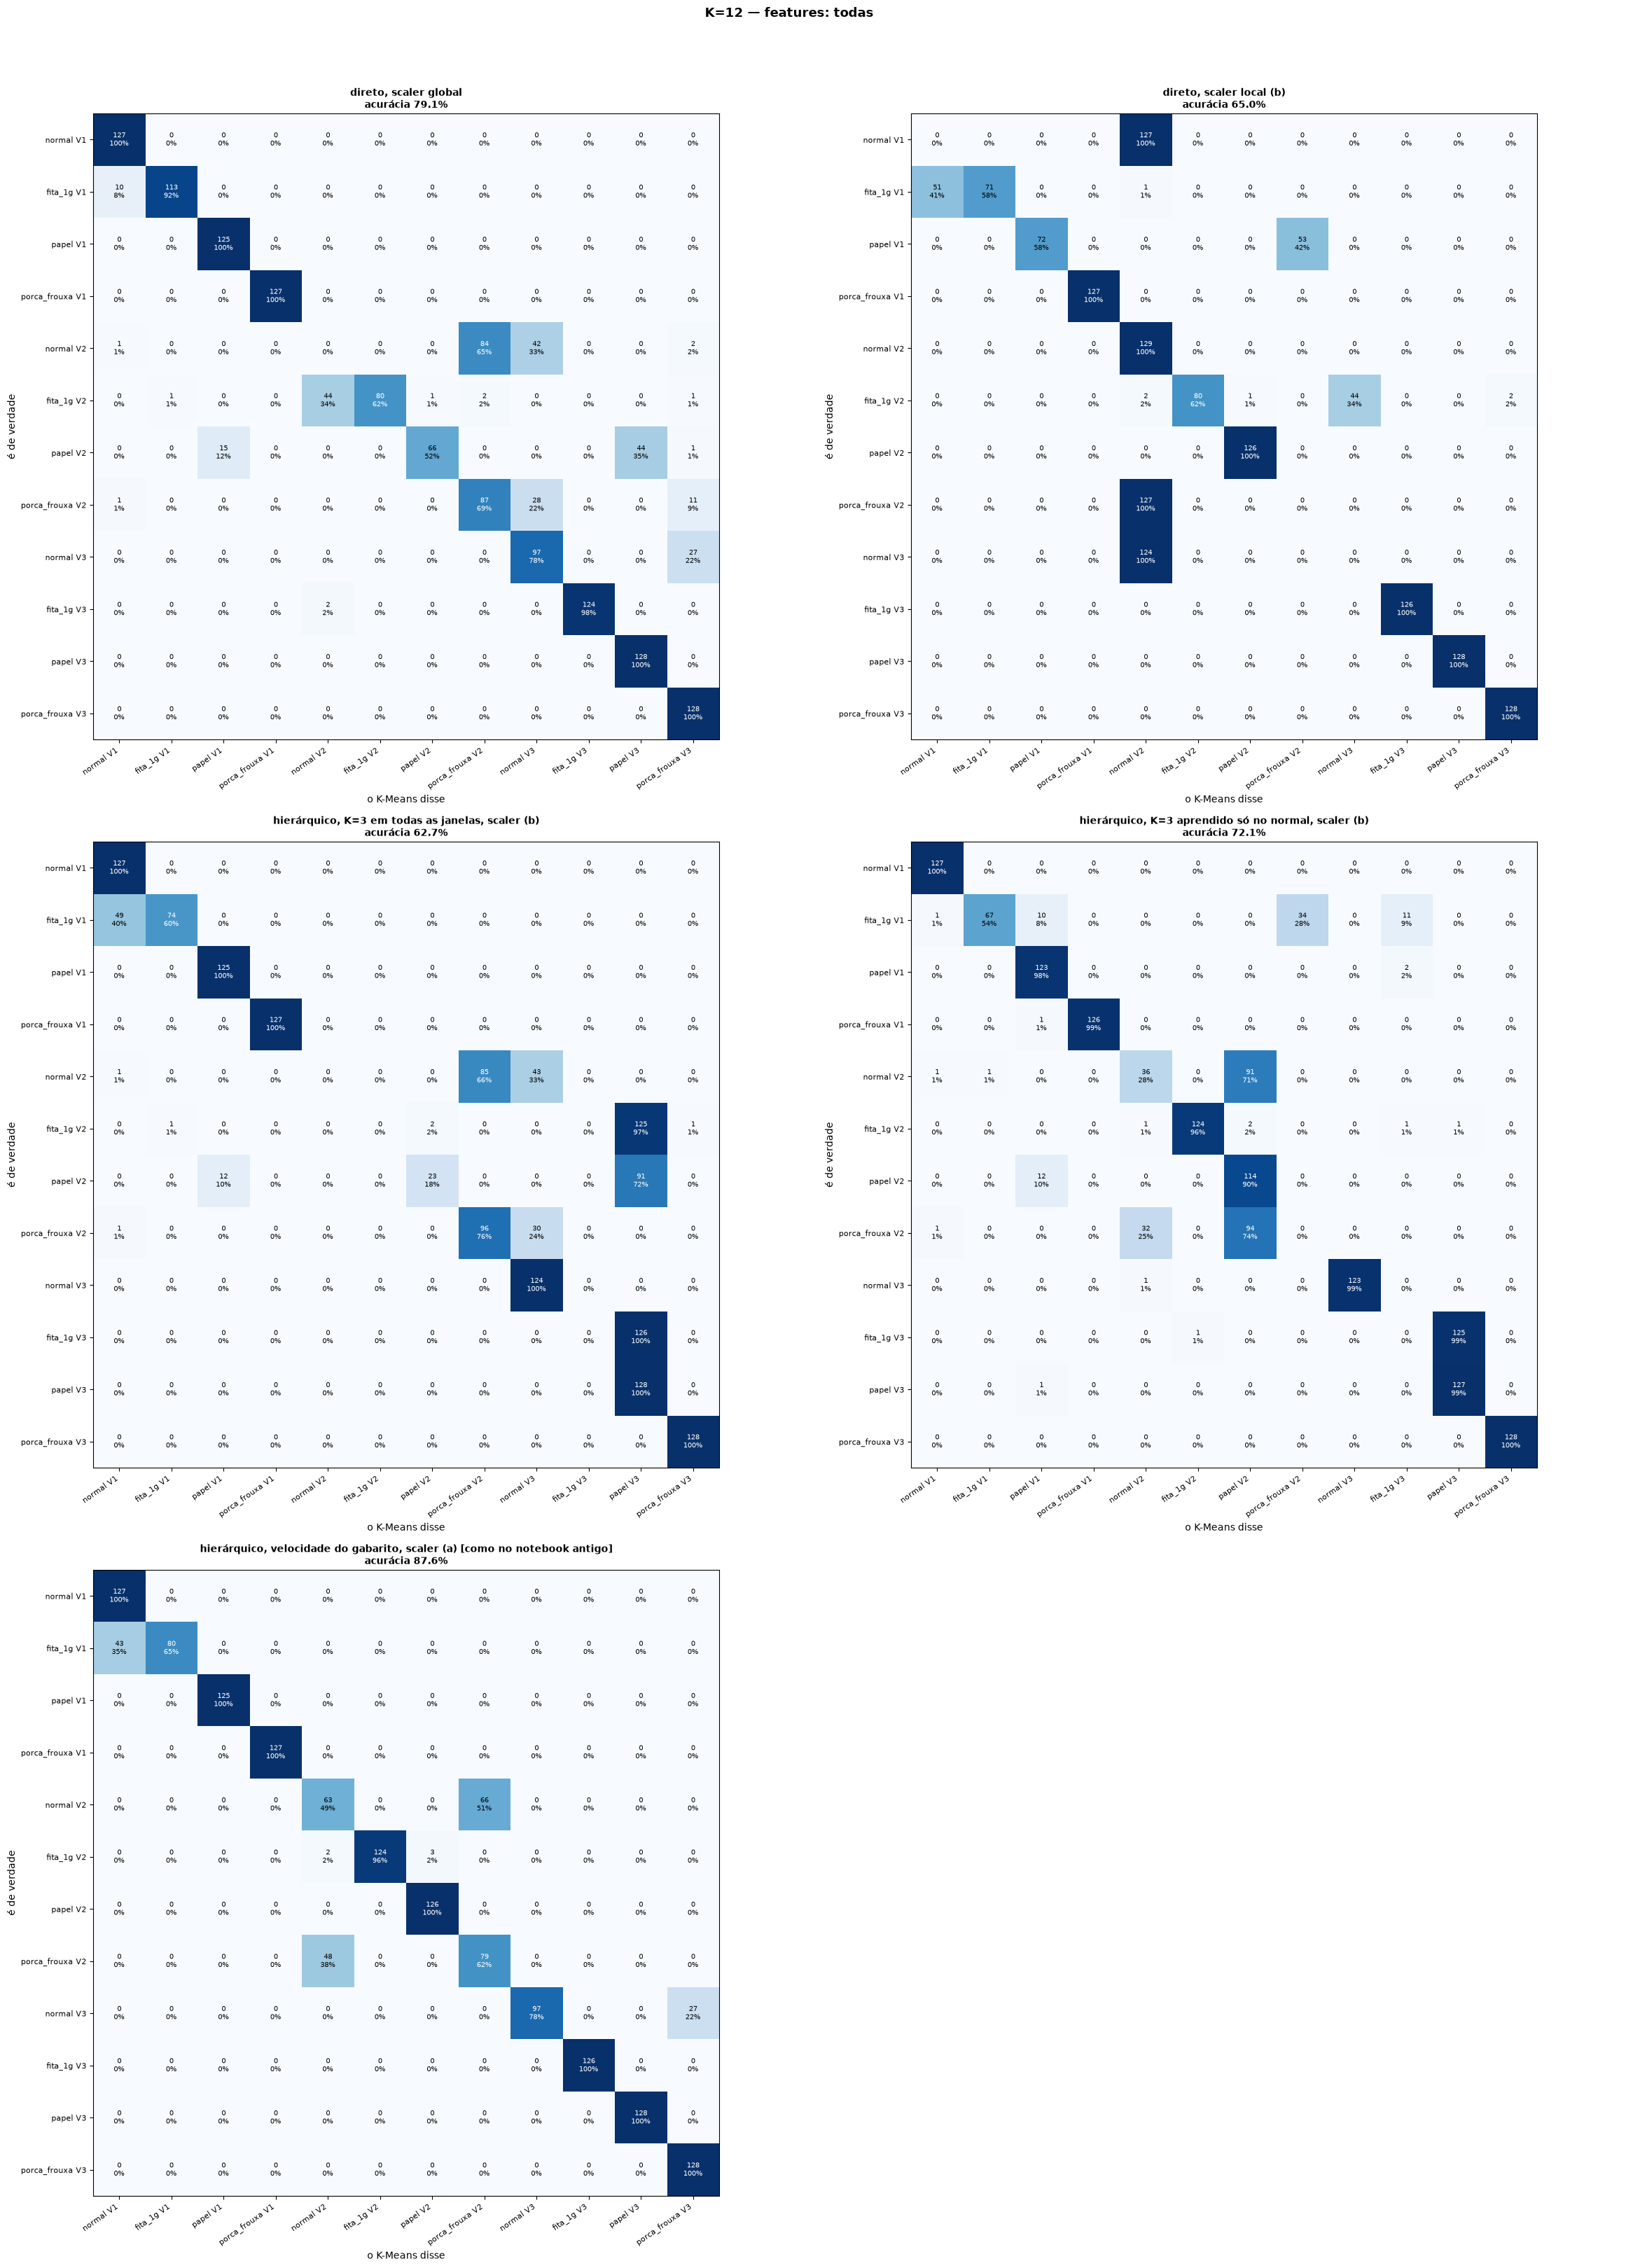

In [35]:
nomes_k6 = list(dict.fromkeys(n for _, n in resultados_k6))
fig, axs = plt.subplots(3, 2, figsize=(24, 33))
axs.ravel()[-1].axis("off")
for ax, nome in zip(axs.ravel(), nomes_k6):
    r = resultados_k6[(CONJUNTO_PRINCIPAL, nome)]
    plotar_matriz_de_confusao(gabarito["classe"].to_numpy(), r["previstos"], ORDEM_CLASSES, nome, ax=ax)
fig.suptitle(f"K={k6} — features: {CONJUNTO_PRINCIPAL}", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 10.1 — Etapa 1: em qual regime de velocidade cada classe caiu?

**O que buscamos:** entender por que os cenários hierárquicos 3 e 4 perdem acurácia. A tabela cruza a classe real (linhas) com o regime de velocidade escolhido na etapa 1 (colunas, numerados pelo K-Means).

* **Ideal:** cada velocidade real, normal e falha, cai num regime só e diferente dos outros.
* **Se a falha de uma velocidade cair no regime de outra,** a etapa 2 vai juntá-la com a falha daquela outra velocidade. O K=12 erra a **velocidade** dessa falha, mas ela ainda pode ser **detectada** como anomalia (10.2).

In [36]:
for nome in ("K=3 em todas as janelas", "K=3 aprendido só no normal"):
    print(f"Etapa 1 — {nome} (features: {CONJUNTO_PRINCIPAL})")
    display(pd.crosstab(gabarito["classe"], etapa1[(CONJUNTO_PRINCIPAL, nome)], rownames=["classe real"], colnames=["regime"]).reindex(ORDEM_CLASSES))

Etapa 1 — K=3 em todas as janelas (features: todas)


regime,0,1,2
classe real,,,
normal V1,0,0,127
fita_1g V1,0,0,123
papel V1,0,0,125
porca_frouxa V1,0,0,127
normal V2,0,128,1
fita_1g V2,125,3,1
papel V2,91,23,12
porca_frouxa V2,0,126,1
normal V3,0,124,0


Etapa 1 — K=3 aprendido só no normal (features: todas)


regime,0,1,2
classe real,,,
normal V1,0,127,0
fita_1g V1,11,102,10
papel V1,2,0,123
porca_frouxa V1,0,126,1
normal V2,36,2,91
fita_1g V2,2,0,127
papel V2,0,0,126
porca_frouxa V2,32,1,94
normal V3,124,0,0


### 10.2 — Os cenários hierárquicos usados como detector (normal × anomalia)

**O que buscamos:** para a manutenção, o mais importante é **detectar** a falha, mesmo que a velocidade atribuída a ela esteja errada. Transformamos os 12 grupos em "normal" ou "anomalia" com uma regra que **não usa o gabarito da falha**, só a referência normal (a mesma informação que o scaler b já usa):

* em cada regime de velocidade, o subgrupo que contém a **maior parte das janelas normais de calibração** é o "normal";
* todos os outros subgrupos, e os regimes sem nenhuma janela normal, são "anomalia".

**Como ler:** recall da anomalia alto e falso alarme baixo = o detector funciona, mesmo que o K=12 tenha errado a velocidade de alguma falha. A segunda tabela abre o cenário 4 por condição e velocidade (na linha do normal, o número é o falso alarme).

In [37]:
def detectar_pelos_grupos(grupos_finais, e_normal):
    """Converte os grupos do hierárquico em normal/anomalia: em cada regime, o subgrupo com mais normais é o normal."""
    grupos = pd.Series(grupos_finais).astype(str)
    regime = grupos.str.split("-").str[0]
    decisao = pd.Series(NOME_ANOMALIA, index=grupos.index)
    for r in regime.unique():
        normais_no_regime = grupos[(regime == r).to_numpy() & e_normal]
        if len(normais_no_regime):
            decisao[grupos == normais_no_regime.value_counts().idxmax()] = NOME_NORMAL
    return decisao.to_numpy()

In [38]:
e_normal = (gabarito["binario"] == NOME_NORMAL).to_numpy()
linhas_detector = []
for (conjunto, nome), r in resultados_k6.items():
    if not nome.startswith("hierárquico"):
        continue
    decisao = detectar_pelos_grupos(r["clusters"], e_normal)
    reais = gabarito["binario"].to_numpy()
    linha = {"cenário": nome, "features": conjunto}
    for falha in condicoes_comparadas:
        sel = (gabarito["condicao"] == falha).to_numpy()
        linha[f"recall {falha} (%)"] = 100 * (decisao[sel] == NOME_ANOMALIA).mean()
    linha[f"recall anomalia geral (%)"] = 100 * (decisao[reais == NOME_ANOMALIA] == NOME_ANOMALIA).mean()
    linha["falso alarme (%)"] = 100 * (decisao[reais == NOME_NORMAL] == NOME_ANOMALIA).mean()
    linhas_detector.append(linha)
tabela_detector = pd.DataFrame(linhas_detector).set_index(["cenário", "features"])
display(tabela_detector.round(1))

nome_cenario_4 = "hierárquico, K=3 aprendido só no normal, scaler (b)"
print(f"% chamada de anomalia por condição e velocidade — {nome_cenario_4}, features {CONJUNTO_PRINCIPAL}")
display(taxa_de_anomalia_por_condicao(gabarito, detectar_pelos_grupos(resultados_k6[(CONJUNTO_PRINCIPAL, nome_cenario_4)]["clusters"], e_normal)).round(1))

,,recall fita_1g (%),recall papel (%),recall porca_frouxa (%),recall anomalia geral (%),falso alarme (%)
cenário,features,,,,,
"hierárquico, K=3 em todas as janelas, scaler (b)",tempo,82.0,100.0,100.0,94.0,66.3
"hierárquico, K=3 aprendido só no normal, scaler (b)",tempo,79.4,99.2,33.2,70.5,13.4
"hierárquico, velocidade do gabarito, scaler (a) [como no notebook antigo]",tempo,85.2,99.7,66.2,83.7,28.2
"hierárquico, K=3 em todas as janelas, scaler (b)",FFT,88.9,100.0,94.2,94.4,25.3
"hierárquico, K=3 aprendido só no normal, scaler (b)",FFT,99.5,100.0,75.9,91.7,10.0
"hierárquico, velocidade do gabarito, scaler (a) [como no notebook antigo]",FFT,88.6,100.0,79.3,89.3,23.9
"hierárquico, K=3 em todas as janelas, scaler (b)",rotação,99.2,49.9,41.1,63.3,37.1
"hierárquico, K=3 aprendido só no normal, scaler (b)",rotação,99.2,43.8,54.2,65.7,17.9
"hierárquico, velocidade do gabarito, scaler (a) [como no notebook antigo]",rotação,99.2,68.9,57.3,75.1,31.8


% chamada de anomalia por condição e velocidade — hierárquico, K=3 aprendido só no normal, scaler (b), features todas


,Vel 1,Vel 2,Vel 3
condicao,,,
normal,0.0,28.7,0.8
fita_1g,99.2,98.4,100.0
papel,100.0,9.5,100.0
porca_frouxa,100.0,25.2,100.0


### 10.3 — Com e sem log: o que o log mudou?

**O que buscamos:** isolar o efeito do log do Passo 3. Repetimos os dois experimentos com scaler global (K=12 direto e K=2 global) **sem aplicar o log**, nos mesmos dados.

**Por que isso importa:** nos dados antigos, o notebook sem log teve **56,51%** no K=6 global. Aqui o K é 12, então os números não se comparam com aquele. O que importa é a diferença **com e sem log nos mesmos dados**: se o com log for bem maior, a melhora vem do log.

In [39]:
def comparar_com_e_sem_log(features, gabarito, conjuntos=CONJUNTOS):
    """K=6 direto e K=2 global, com scaler global, com e sem log."""
    linhas = []
    anomalia_v1 = ((gabarito["velocidade"] == velocidades[0]) & (gabarito["binario"] == NOME_ANOMALIA)).to_numpy()
    for usar_log in (True, False):
        for nome, colunas in conjuntos.items():
            padronizada = padronizar_global(aplicar_log(features, colunas, aplicar=usar_log))
            metricas_k6, _ = calcular_metricas(gabarito["classe"], rodar_kmeans(padronizada, len(ORDEM_CLASSES)), ORDEM_CLASSES)
            metricas_k2, previstos_k2 = calcular_metricas(gabarito["binario"], rodar_kmeans(padronizada, 2), classes_binarias)
            linhas.append({"log": "com log" if usar_log else "sem log", "features": nome,
                           f"K={len(ORDEM_CLASSES)} direto, acurácia (%)": metricas_k6["acurácia (%)"],
                           "K=2 global, acurácia (%)": metricas_k2["acurácia (%)"],
                           f"K=2 global, recall anomalia V{velocidades[0]} (%)": 100 * (previstos_k2[anomalia_v1] == NOME_ANOMALIA).mean()})
    return pd.DataFrame(linhas).set_index(["features", "log"]).sort_index()

In [40]:
display(comparar_com_e_sem_log(features, gabarito).round(2))

K=12 direto, acurácia (%)  K=2 global, acurácia (%)  \
features log                                                            
FFT      com log                      76.17                     57.08   
         sem log                      55.10                     66.82   
rotação  com log                      59.25                     55.56   
         sem log                      31.60                     58.72   
tempo    com log                      65.96                     58.13   
         sem log                      63.53                     58.53   
todas    com log                      79.13                     56.16   
         sem log                      65.24                     58.53   

                  K=2 global, recall anomalia V1 (%)  
features log                                          
FFT      com log                                0.53  
         sem log                              100.00  
rotação  com log                                0.00  
         sem log                              100.00  
tempo    com log                                5.33  
         sem log                              100.00  
todas    com log                                0.00  
         sem log                              100.00

### Conclusões do Passo 10 (nesta execução)

**Acurácia nos 12 grupos (todas as features):**

| Cenário | Acurácia | ARI |
| --- | --- | --- |
| 1. Direto, scaler global | **79,1%** | 0,72 |
| 2. Direto, scaler local (b) | 65,0% | 0,56 |
| 3. Hierárquico, K=3 em todas as janelas | 62,7% | 0,51 |
| 4. Hierárquico, K=3 aprendido só no normal | 72,1% | 0,68 |
| 5. Hierárquico, velocidade do gabarito (usa rótulo) | **87,6%** | 0,82 |

* **O K=12 direto com scaler global foi o melhor dos cenários sem rótulo.** Diferente dos dados antigos, aqui as falhas são tão distintas entre si (Notebook 02) que a régua global já separa boa parte delas.
  * **Na Vel 1, as quatro condições ficam quase perfeitas:** normal 100%, fita 92%, papel 100%, porca 100%.
  * **A Vel 2 é a bagunça:** o normal V2 e a porca V2 caem nos mesmos grupos, a fita V2 se divide em dois grupos e o papel V2 se mistura com o papel V3.
* **Etapa 1 do cenário 4 (10.1):** o K=3 aprendido no normal coloca **36 janelas do normal V2 no regime da Vel 3** (a partida a frio do Passo 6), e a porca V2 vai junto (32 janelas).
* **O detector do cenário 4 (10.2):** recall geral de 81% com **falso alarme de 10%**.
  * **Vel 1 e 3:** todas as falhas detectadas, com falso alarme de 0% a 0,8%.
  * **Vel 2:** papel 9,5%, porca 25%, falso alarme 28,7%.
  * **De novo, a Vel 2 é o problema.**
* **O cenário 3** chega a 93% de recall, mas com **22% de falso alarme**: ele acusa demais.
* **Com e sem log (10.3):** o log ajuda muito no K=12 direto (79,1% com log contra 65,2% sem). No K=2 global, o "100% de recall na Vel 1" sem log é **ilusão do alinhamento**:
  * o K=2 separou a fita V2 e V3 de **todo o resto**;
  * o grupo "resto" tinha mais janelas de falha do que normais, então foi chamado de "anomalia";
  * com isso, o normal inteiro virou falso alarme.
  * É o exemplo do Passo 5 na prática: **sempre olhe o falso alarme junto com o recall**.

## Passo 11 — Silhueta: quantos grupos os dados "pedem", sem olhar rótulos?

**O que buscamos:** até aqui nós **dissemos** ao K-Means quantos grupos procurar (3, 2, 6). Agora perguntamos o contrário: **se não soubéssemos nada, qual K os próprios dados indicariam?**

**O que é a silhueta:** para cada janela, compara a distância média até as janelas **do próprio grupo** com a distância até o **grupo vizinho mais próximo**.

* **Perto de 1:** a janela está bem dentro do seu grupo e longe dos outros.
* **Perto de 0:** está na fronteira entre dois grupos.
* **Negativa:** provavelmente está no grupo errado.

A silhueta média de todas as janelas dá uma nota para cada K. **O K com a maior nota é o que os dados sugerem.**

**Como ler:** se a curva tem o pico em K=2 dentro de cada velocidade (scaler local b), os dados se dividem naturalmente em dois grupos, o que bate com normal e falha. Se o pico estiver em outro K (por exemplo, 4), pode haver subgrupos escondidos, como a fase do ciclo ou o início e o fim de uma gravação com deriva.

In [41]:
def calcular_silhuetas(padronizada, valores_k=K_SILHUETA):
    """Silhueta média para cada K."""
    return pd.Series({k: silhouette_score(padronizada.to_numpy(), rodar_kmeans(padronizada, k)) for k in valores_k})

,"só normal, scaler global","só anomalia, scaler global","todas, scaler global","Vel 1, scaler local (b)","Vel 2, scaler local (b)","Vel 3, scaler local (b)"
2,0.440,0.320,0.338,0.400,0.549,0.566
3,0.375,0.291,0.272,0.325,0.428,0.631
4,0.315,0.281,0.293,0.385,0.401,0.470
5,0.291,0.303,0.316,0.371,0.399,0.371
6,0.271,0.333,0.335,0.353,0.276,0.263
7,0.282,0.345,0.335,0.360,0.279,0.265
8,0.280,0.363,0.324,0.307,0.287,0.237


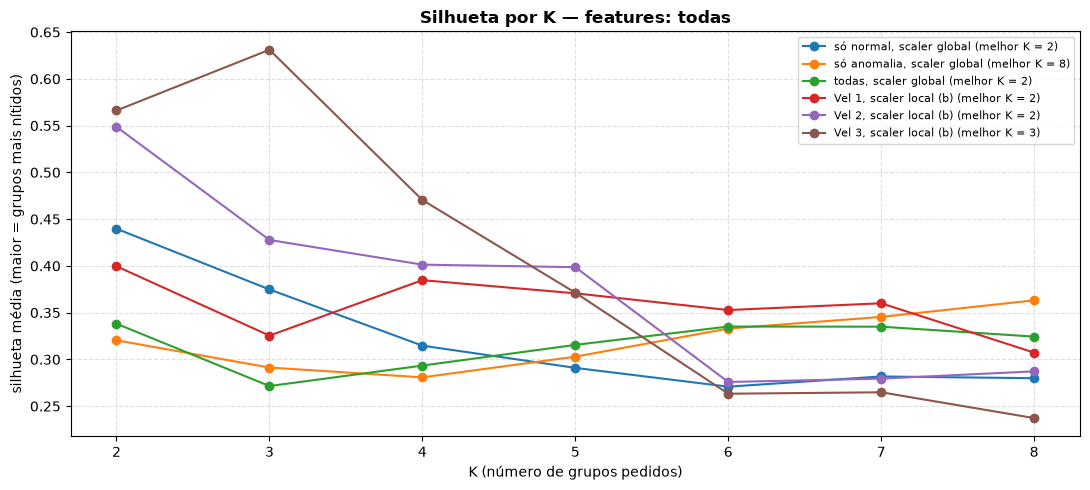

In [42]:
curvas = {}
matriz_principal = aplicar_log(features, CONJUNTOS[CONJUNTO_PRINCIPAL])
curvas["só normal, scaler global"] = calcular_silhuetas(padronizar_global(matriz_principal.loc[so_normal]))
curvas["só anomalia, scaler global"] = calcular_silhuetas(padronizar_global(matriz_principal.loc[so_anomalia]))
curvas["todas, scaler global"] = calcular_silhuetas(padronizar_global(matriz_principal))
for velocidade in velocidades:
    sel = (gabarito["velocidade"] == velocidade).to_numpy()
    curvas[f"Vel {velocidade}, scaler local (b)"] = calcular_silhuetas(padronizar(matriz_principal.loc[sel], gabarito.loc[sel], "local_b"))

silhuetas = pd.DataFrame(curvas)
display(silhuetas.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
for nome in silhuetas.columns:
    ax.plot(silhuetas.index, silhuetas[nome], marker="o", label=f"{nome} (melhor K = {silhuetas[nome].idxmax()})")
ax.set_xlabel("K (número de grupos pedidos)")
ax.set_ylabel("silhueta média (maior = grupos mais nítidos)")
ax.set_title(f"Silhueta por K — features: {CONJUNTO_PRINCIPAL}", fontsize=12, fontweight="bold")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Conclusões do Passo 11 (nesta execução)

* **Só normal, scaler global:** a melhor silhueta é em **K=2** (0,44), e não em K=3. O normal se divide mais facilmente em dois grupos do que nas três velocidades. Uma explicação compatível com o Passo 6: a Vel 3 e o começo frio da Vel 2 de um lado, e a Vel 1 do outro.
* **Vel 3 com scaler (b):** pico em **K=3** (0,63). Isso bate com o resultado do 9.2: na Vel 3, normal e porca formam um grupo, e fita e papel formam grupos distintos.
* **Vel 1 e Vel 2 com scaler (b):** pico em K=2, mas com silhuetas modestas (0,40 e 0,55).
* **Todas as janelas e só as falhas, scaler global:** silhuetas baixas (0,32 a 0,36), sem um pico claro. Não existe um número "natural" de grupos para 12 classes.
* **Leitura:** a silhueta **não recupera as 4 condições**. Os dados têm estrutura, mas ela mistura falha, velocidade e aquecimento. Isso reforça a necessidade de usar **rótulos** (Notebook 05) e de um detector baseado no **normal** (Notebook 06).

## Passo 12 — Checagens anti-ilusão

**O que buscamos:** ter certeza de que um bom resultado vem **da falha** e não de algum efeito paralelo nos dados. São quatro checagens:

1. **Erros no tempo (12.1):** onde, ao longo da gravação, o K-Means erra?
2. **Deriva e fase (12.2):** o Normal sozinho já se divide em dois grupos?
3. **Estabilidade (12.3):** o resultado depende do sorteio inicial do K-Means?
4. **Janelas atípicas (12.4):** poucas janelas estranhas estão puxando o resultado?

### 12.1 — Erros no tempo

**Como ler o gráfico:** cada faixa é uma gravação, com as janelas em ordem de tempo (da esquerda para a direita). O ponto fica em cima se o K-Means disse "anomalia" e embaixo se disse "normal". **Verde = acerto, X vermelho = erro.**

O que procurar:

* **Erros espalhados e raros:** ruído normal.
* **Erros juntos no começo ou no fim:** problema na gravação (manuseio) ou **aquecimento**. Nos dados novos, nas Vel 1 e 2, a rotação sobe ao longo da gravação (Notebook 03, Passo 7.3). Se os erros do normal ficarem todos no fim, o K-Means confundiu "motor quente" com falha.
* **Erros em ritmo regular:** o ciclo da oscilação. O ciclo dura cerca de 18 s na Vel 1, 12 s na Vel 2 e 10 s na Vel 3 (Notebook 03, Passo 7.2.1), então janelas de 5 s pegam fases diferentes do ciclo.

**O gráfico usa o 9.1** (normal × cada falha, scaler b): uma coluna por falha e, em cada velocidade, duas faixas, a gravação normal e a da falha daquele mesmo K=2. A tabela embaixo conta os erros por terço da gravação: se quase todos estiverem no 1º ou no 3º terço, o K=2 está separando **começo × fim**.
* **Uma gravação inteira errada:** o grupo não separou aquela condição.

In [43]:
def plotar_erros_no_tempo_por_falha(resultados_por_falha, conjunto):
    """Uma coluna por falha; em cada velocidade, a gravação normal e a da falha do mesmo K=2. Verde = acerto, X vermelho = erro."""
    n_linhas = 2 * len(velocidades)
    fig, axs = plt.subplots(n_linhas, len(condicoes_comparadas), figsize=(6.2 * len(condicoes_comparadas), 1.35 * n_linhas + 1.5),
                            sharex=True, squeeze=False)
    for coluna, falha in enumerate(condicoes_comparadas):
        for iv, velocidade in enumerate(velocidades):
            r = resultados_por_falha[(falha, velocidade, conjunto)]
            for k, condicao in enumerate((NOME_NORMAL, falha)):
                ax = axs[2 * iv + k, coluna]
                sel = (r["rotulos"]["condicao"] == condicao).to_numpy()
                janelas = r["rotulos"]["janela"].to_numpy()[sel]
                previsto_anomalia = (r["previstos"][sel] == NOME_ANOMALIA).astype(int)
                acerto = r["previstos"][sel] == r["reais"][sel]
                ax.scatter(janelas[acerto], previsto_anomalia[acerto], s=10, color="tab:green")
                ax.scatter(janelas[~acerto], previsto_anomalia[~acerto], s=20, color="tab:red", marker="x")
                ax.set_yticks([0, 1])
                ax.set_yticklabels([NOME_NORMAL, NOME_ANOMALIA], fontsize=7)
                ax.set_ylim(-0.5, 1.5)
                ax.set_title(f"{condicao} Vel {velocidade} (no K=2 normal × {falha}) — {(~acerto).sum()} erros em {len(acerto)}",
                             fontsize=8, fontweight="bold", loc="left")
    for ax in axs[-1]:
        ax.set_xlabel(f"janela (cada uma = {JANELA_S} s)")
    fig.suptitle(f"K=2 por velocidade, normal × cada falha, scaler local (b), features {conjunto}: o que foi dito em cada janela",
                 fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

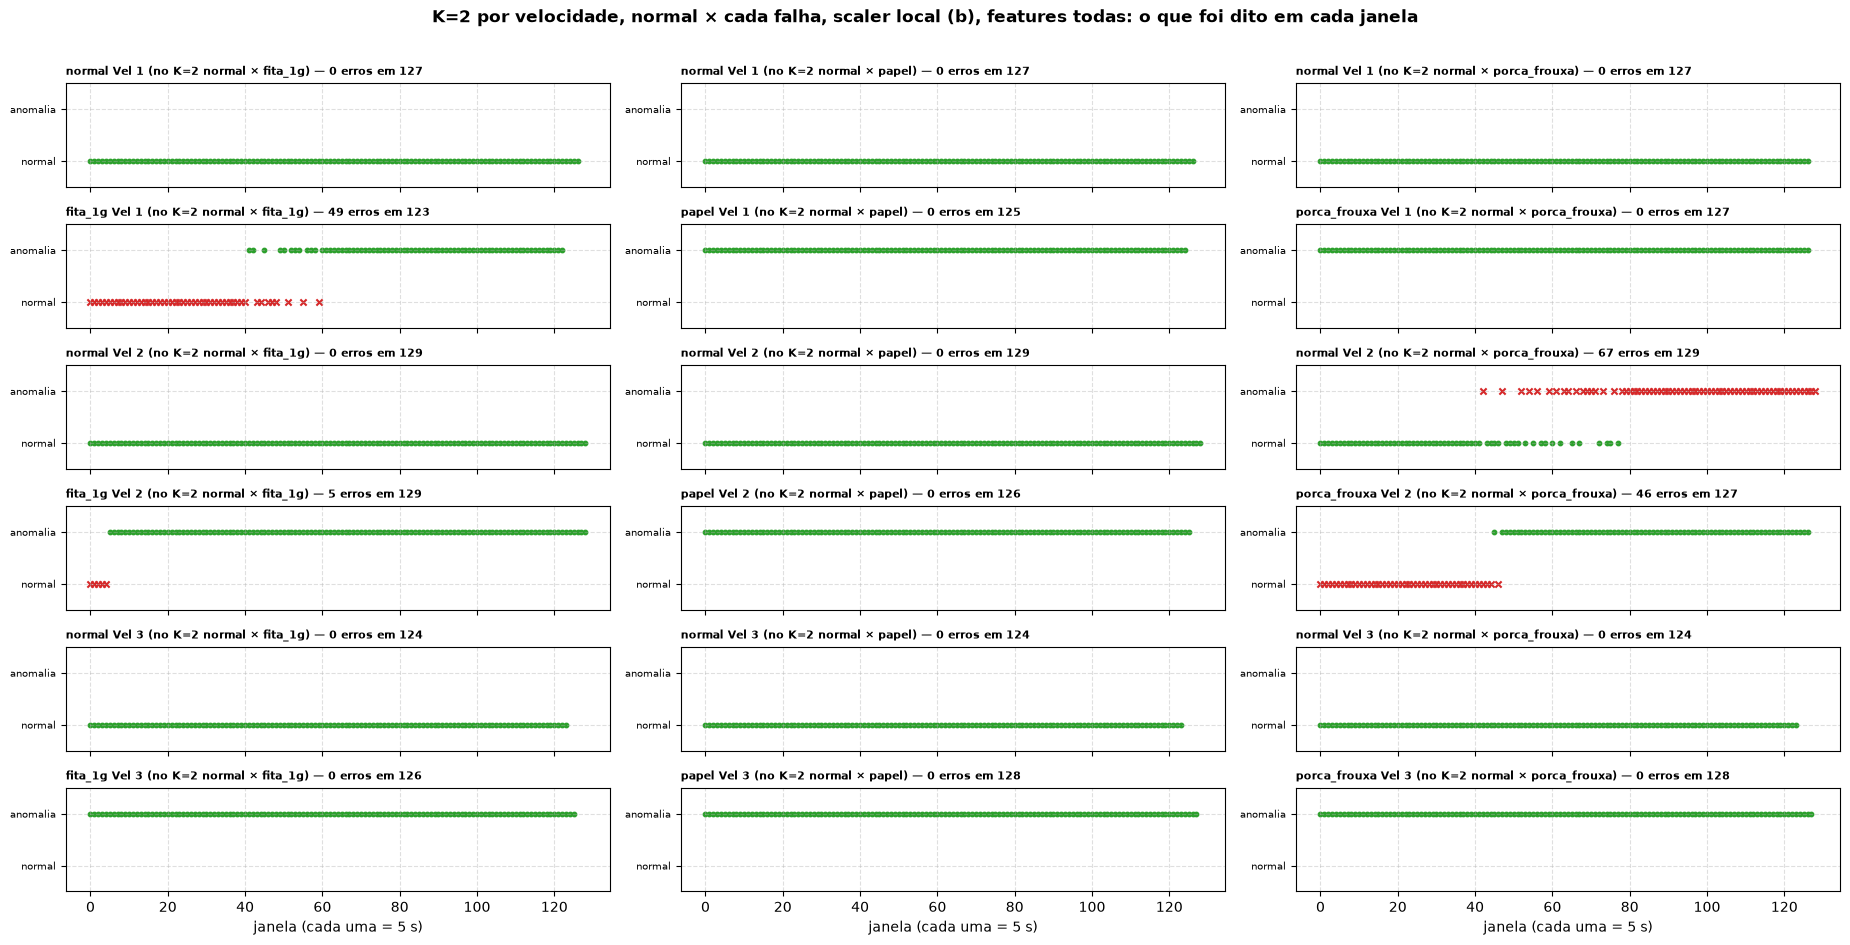

Erros por terço da gravação (9.1, scaler b):


terço                                       1º terço  2º terço  3º terço  \
experimento        base                                                    
fita_1g Vel 1      fita_1g_vel_1                41.0       8.0       0.0   
fita_1g Vel 2      fita_1g_vel_2                 5.0       0.0       0.0   
porca_frouxa Vel 2 porca_frouxa_vel_2           43.0       3.0       0.0   
                   ventilador_normal_vel_2       1.0      23.0      43.0   

terço                                       total de erros  janelas  
experimento        base                                              
fita_1g Vel 1      fita_1g_vel_1                      49.0      123  
fita_1g Vel 2      fita_1g_vel_2                       5.0      129  
porca_frouxa Vel 2 porca_frouxa_vel_2                 46.0      127  
                   ventilador_normal_vel_2            67.0      129

In [44]:
plotar_erros_no_tempo_por_falha(resultados_k2_falha_b, CONJUNTO_PRINCIPAL)

print("Erros por terço da gravação (9.1, scaler b):")
display(pd.concat({f"{f} Vel {v}": erros_por_terco(resultados_k2_falha_b[(f, v, CONJUNTO_PRINCIPAL)])
                   for f in condicoes_comparadas for v in velocidades}, names=["experimento", "base"]))

### 12.2 — Só o Normal, em duas metades: a deriva vira "grupo"?

**O que buscamos:** pegar **só as janelas normais** de cada velocidade e pedir K=2. Se não houvesse deriva nem ciclo, os dois grupos seriam arbitrários. Comparamos os grupos com dois "rótulos de mentira":

* **metade da gravação** (primeira ou segunda metade): ARI alto = o K-Means separa **início contra fim** (deriva, por exemplo aquecimento);
* **janela par ou ímpar**: ARI alto = o K-Means separa **fase forte contra fase fraca** do ciclo (com 5 s, janelas vizinhas alternam).

**Por que importa:** se o normal sozinho já se divide em dois grupos nítidos, um K=2 com falha pode estar separando a deriva e não a falha. Nos dados novos, o aquecimento leva a rotação do normal Vel 1 de cerca de 11,0 para 13,4 Hz (Notebook 03, Passo 7.3). **Este é o teste mais importante do notebook para o aquecimento.**

In [45]:
def testar_deriva_e_fase(features, gabarito, colunas):
    """K=2 só nas normais de cada velocidade, comparado com 'metade da gravação' e 'janela par/ímpar'."""
    linhas = []
    for velocidade in velocidades:
        sel = ((gabarito["velocidade"] == velocidade) & (gabarito["binario"] == NOME_NORMAL)).to_numpy()
        rotulos = gabarito.loc[sel]
        clusters = rodar_kmeans(padronizar_global(aplicar_log(features.loc[sel], colunas)), 2)
        posicao = rotulos.groupby("base")["janela"].rank(pct=True)
        metade = np.where(posicao > 0.5, "2ª metade", "1ª metade")
        paridade = np.where(rotulos["janela"] % 2 == 0, "par", "ímpar")
        linhas.append({"velocidade": velocidade, "janelas": int(sel.sum()),
                       "tamanho do menor grupo (%)": 100 * np.bincount(clusters).min() / len(clusters),
                       "ARI com metade da gravação": adjusted_rand_score(metade, clusters),
                       "ARI com janela par/ímpar": adjusted_rand_score(paridade, clusters)})
    return pd.DataFrame(linhas).set_index("velocidade")

In [46]:
display(testar_deriva_e_fase(features, gabarito, CONJUNTOS[CONJUNTO_PRINCIPAL]).round(3))

,janelas,tamanho do menor grupo (%),ARI com metade da gravação,ARI com janela par/ímpar
velocidade,,,,
1,127,44.094,0.762,-0.007
2,129,34.884,0.494,-0.007
3,124,35.484,0.261,-0.008


### 12.3 — Estabilidade: o resultado muda com a semente?

**O que buscamos:** o K-Means começa de centros sorteados. Se o resultado mudar muito conforme o sorteio, ele não é confiável. Rodamos o K=2 por velocidade (scaler b) com `N_SEMENTES_ESTABILIDADE` sementes diferentes, em cada par normal × falha do 9.1 e no normal × todas as falhas do 9.2, e comparamos os agrupamentos entre si pelo ARI.

* **ARI entre sementes ≈ 1:** sempre os mesmos grupos. Resultado estável.
* **ARI baixo:** os grupos mudam com o sorteio. Desconfie.

In [47]:
def testar_estabilidade(features, gabarito, colunas, n_sementes=N_SEMENTES_ESTABILIDADE):
    """ARI médio e mínimo entre os agrupamentos com sementes diferentes, por par (normal × falha) e velocidade."""
    linhas = []
    pares = {falha: [NOME_NORMAL, falha] for falha in condicoes_comparadas}
    pares["todas as falhas"] = ORDEM_CONDICOES
    for nome, condicoes in pares.items():
        for velocidade in velocidades:
            sel = ((gabarito["velocidade"] == velocidade) & gabarito["condicao"].isin(condicoes)).to_numpy()
            padronizada = padronizar(aplicar_log(features.loc[sel], colunas), gabarito.loc[sel], "local_b")
            agrupamentos = [KMeans(n_clusters=2, n_init=1, random_state=s).fit_predict(padronizada.to_numpy()) for s in range(n_sementes)]
            aris = [adjusted_rand_score(agrupamentos[i], agrupamentos[j]) for i in range(n_sementes) for j in range(i + 1, n_sementes)]
            linhas.append({"normal ×": nome, "velocidade": velocidade,
                           "ARI médio entre sementes": np.mean(aris), "ARI mínimo entre sementes": np.min(aris)})
    return pd.DataFrame(linhas).set_index(["normal ×", "velocidade"])

In [48]:
display(testar_estabilidade(features, gabarito, CONJUNTOS[CONJUNTO_PRINCIPAL]).round(3))

ARI médio entre sementes  \
normal ×        velocidade                             
fita_1g         1                              0.948   
                2                              1.000   
                3                              1.000   
papel           1                              1.000   
                2                              1.000   
                3                              1.000   
porca_frouxa    1                              1.000   
                2                              0.970   
                3                              1.000   
todas as falhas 1                              0.734   
                2                              1.000   
                3                              1.000   

                            ARI mínimo entre sementes  
normal ×        velocidade                             
fita_1g         1                               0.903  
                2                               1.000  
                3                               1.000  
papel           1                               1.000  
                2                               1.000  
                3                               1.000  
porca_frouxa    1                               1.000  
                2                               0.849  
                3                               1.000  
todas as falhas 1                               0.251  
                2                               1.000  
                3                               1.000

### 12.4 — Janelas atípicas: o resultado depende delas?

**O que buscamos:** o Notebook 03 encontrou janelas muito fora do padrão (o trecho inicial da fita Vel 2, em que a vibração ainda está crescendo, e a janela de partida da Vel 3). O K-Means é sensível a pontos extremos, porque eles puxam os centros. Encontramos essas janelas com o mesmo critério do Notebook 03 e refazemos o K=2 por velocidade do 9.1 (normal × cada falha) **sem elas**.

* Se o resultado não muda, ele não depende dessas janelas.
* Se melhora muito, essas janelas estavam distorcendo os grupos e vale investigar a gravação.

In [49]:
def encontrar_janelas_atipicas(features, colunas, limite_z=LIMITE_Z_ROBUSTO, min_features=MIN_FEATURES_ATIPICAS):
    """Janelas com muitas features a mais de limite_z desvios robustos (MAD) da mediana do seu grupo."""
    atipicas = pd.Series(False, index=features.index)
    for _, grupo in features.groupby(["condicao", "velocidade"]):
        valores = grupo[colunas]
        mediana = valores.median()
        desvio_robusto = 1.4826 * (valores - mediana).abs().median()
        z_robusto = (valores - mediana) / desvio_robusto.replace(0, np.nan)
        atipicas.loc[grupo.index] = (z_robusto.abs() > limite_z).sum(axis=1) >= min_features
    return atipicas

In [50]:
atipicas = encontrar_janelas_atipicas(features, COLUNAS_TODAS)
print(f"{int(atipicas.sum())} janelas atípicas:")
display(gabarito.loc[atipicas].groupby("base")["janela"].apply(list).to_frame("janelas"))

if atipicas.any():
    sem_atipicas = ~atipicas
    tabela_sem, _ = k2_por_falha(features.loc[sem_atipicas], gabarito.loc[sem_atipicas], "local_b",
                                 {CONJUNTO_PRINCIPAL: CONJUNTOS[CONJUNTO_PRINCIPAL]})
    com = tabela_k2_falha_b[tabela_k2_falha_b["features"] == CONJUNTO_PRINCIPAL].set_index(["falha", "velocidade"])
    sem = tabela_sem.set_index(["falha", "velocidade"])
    colunas_comparadas = ["acurácia (%)", f"recall {NOME_ANOMALIA} (%)", "falso alarme (%)", "ARI"]
    display(pd.concat({"com as atípicas": com[colunas_comparadas], "sem as atípicas": sem[colunas_comparadas]}, axis=1).round(2))

36 janelas atípicas:


,janelas
base,
fita_1g_vel_2,"[2, 5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17..."
fita_1g_vel_3,"[0, 35, 67, 107, 109]"
papel_vel_3,[0]


com as atípicas                                       \
                           acurácia (%) recall anomalia (%) falso alarme (%)   
falha        velocidade                                                        
fita_1g      1                    80.40               60.16             0.00   
             2                    98.06               96.12             0.00   
             3                   100.00              100.00             0.00   
papel        1                   100.00              100.00             0.00   
             2                   100.00              100.00             0.00   
             3                   100.00              100.00             0.00   
porca_frouxa 1                   100.00              100.00             0.00   
             2                    55.86               63.78            51.94   
             3                   100.00              100.00             0.00   

                              sem as atípicas                      \
                          ARI    acurácia (%) recall anomalia (%)   
falha        velocidade                                             
fita_1g      1           0.37           80.40               60.16   
             2           0.92           98.25               95.96   
             3           1.00          100.00              100.00   
papel        1           1.00          100.00              100.00   
             2           1.00          100.00              100.00   
             3           1.00          100.00              100.00   
porca_frouxa 1           1.00          100.00              100.00   
             2           0.01           55.86               63.78   
             3           1.00          100.00              100.00   

                                                
                        falso alarme (%)   ARI  
falha        velocidade                         
fita_1g      1                      0.00  0.37  
             2                      0.00  0.93  
             3                      0.00  1.00  
papel        1                      0.00  1.00  
             2                      0.00  1.00  
             3                      0.00  1.00  
porca_frouxa 1                      0.00  1.00  
             2                     51.94  0.01  
             3                      0.00  1.00

### Conclusões do Passo 12 (nesta execução)

**12.1 — Erros no tempo:**
* **Porca V2:** o K=2 cortou as duas gravações **no tempo**. O 1º terço das duas foi para um grupo e o fim das duas para o outro. Os erros estão em 43 de 46 janelas da porca no 1º terço, e em 66 de 67 janelas do normal no 2º e 3º terços.
* **Fita V1:** 41 dos 49 erros estão no 1º terço. A fita só passa a ser detectada depois dos primeiros cerca de 3 minutos.
* **Fita V2:** 5 erros, todos nas primeiras 5 janelas (a partida).
* **Os outros 6 pares (papel nas três velocidades, porca V1 e V3, fita V3):** nenhum erro.

**12.2 — Só o normal, K=2:**
* O ARI com "metade da gravação" é **0,76 na Vel 1**, 0,49 na Vel 2 e 0,26 na Vel 3.
* Ou seja, **o normal da Vel 1 sozinho já se divide em "começo × fim"** quase perfeitamente. **Essa é a prova direta do aquecimento.**
* O ARI com "janela par × ímpar" é cerca de 0 em todas as velocidades: a fase do ciclo **não** forma grupos.

**12.3 — Estabilidade:**
* Pares normal × uma falha: ARI entre sementes de 0,95 a 1,00. Os resultados são estáveis (o pior caso é a porca V2, com mínimo de 0,85).
* Normal × todas as falhas na Vel 1: mínimo de **0,25**. Com as falhas misturadas, o K=2 tem várias divisões "boas" e muda conforme a semente. É mais um sinal de que o 9.2 não é um bom detector.

**12.4 — Janelas atípicas:**
* São 36: o trecho inicial da fita V2 e as janelas de partida da Vel 3.
* Tirá-las **não muda nada importante**: fita V2 de 96,1% para 96,0%, e o resto igual.

## Resumo de todos os experimentos

**O que buscamos:** uma tabela única com todos os experimentos, scalers e conjuntos de features, para comparar de relance e levar as decisões ao Notebook 05.

**Como ler:** a coluna "destaque" traz a medida mais importante de cada experimento quando a acurácia sozinha pode enganar (por exemplo, o pior recall da anomalia entre as velocidades).

In [51]:
resumo = pd.DataFrame(RESUMO).set_index(["experimento", "scaler", "features"])
display(resumo.round(2))

acurácia (%)  \
experimento                  scaler                                             features                 
K=3 só normal (velocidades)  global                                             tempo            99.21   
                                                                                FFT              90.00   
                                                                                rotação          99.21   
                                                                                todas            90.00   
K=3 só fita_1g (velocidades) global                                             tempo            98.68   
...                                                                                                ...   
K=12 (velocidade x condição) direto, scaler global                              todas            79.13   
                             direto, scaler local (b)                           todas            64.98   
                             hierárquico, K=3 em todas as janelas, scaler (b)   todas            62.67   
                             hierárquico, K=3 aprendido só no normal, scaler... todas            72.09   
                             hierárquico, velocidade do gabarito, scaler (a)... todas            87.56   

                                                                                           ARI  \
experimento                  scaler                                             features         
K=3 só normal (velocidades)  global                                             tempo     0.98   
                                                                                FFT       0.75   
                                                                                rotação   0.98   
                                                                                todas     0.74   
K=3 só fita_1g (velocidades) global                                             tempo     0.96   
...                                                                                        ...   
K=12 (velocidade x condição) direto, scaler global                              todas     0.72   
                             direto, scaler local (b)                           todas     0.56   
                             hierárquico, K=3 em todas as janelas, scaler (b)   todas     0.51   
                             hierárquico, K=3 aprendido só no normal, scaler... todas     0.68   
                             hierárquico, velocidade do gabarito, scaler (a)... todas     0.82   

                                                                                         destaque  
experimento                  scaler                                             features           
K=3 só normal (velocidades)  global                                             tempo         NaN  
                                                                                FFT           NaN  
                                                                                rotação       NaN  
                                                                                todas         NaN  
K=3 só fita_1g (velocidades) global                                             tempo         NaN  
...                                                                                           ...  
K=12 (velocidade x condição) direto, scaler global                              todas         NaN  
                             direto, scaler local (b)                           todas         NaN  
                             hierárquico, K=3 em todas as janelas, scaler (b)   todas         NaN  
                             hierárquico, K=3 aprendido só no normal, scaler... todas         NaN  
                             hierárquico, velocidade do gabarito, scaler (a)... todas         NaN  

[76 rows x 3 columns]

### Decisões e o que levar para o Notebook 05 (dados novos)

**O que o K-Means mostrou, sem rótulos:**

1. **A velocidade é descoberta sem rótulo**, desde que se use **features de rotação ou de tempo** (99,2% no normal). Com todas as features, a partida a frio da Vel 2 vai para a Vel 3.
2. **Cada falha, sozinha contra o normal, se separa na maioria dos casos:** papel 100%, porca 100% nas Vel 1 e 3, fita 96% a 100% nas Vel 2 e 3.
3. **Dois casos falham, e os dois por causa do aquecimento:**
   * **porca V2:** o K=2 separou começo × fim, não porca × normal;
   * **fita V1:** os primeiros cerca de 3 minutos não são detectados.
4. **Com as falhas misturadas, o K=2 não serve como detector:** ele separa a falha mais diferente do resto. Para detectar, a medida certa é **"distância do normal"**, e não "dois grupos".
5. **O K=12 direto com scaler global chega a 79%**, e 87,6% quando a velocidade é conhecida. A Vel 2 é sempre a mais difícil.

**Decisões:**

| Decisão | Por quê |
| --- | --- |
| **Scaler local (b) continua o principal** | Mede "o quanto foge do normal", que é a pergunta do detector. |
| **Log em tudo menos a curtose** | O log ajudou muito no K=12 (79% contra 65%). |
| **Primeiro modelo (velocidade): features de rotação** | Separa as velocidades com 99%, com ou sem falha. |
| **Detector: distância do normal (Notebook 06)**, e não K=2 | O K=2 falha com falhas misturadas. |
| **Manter todas as janelas** | As atípicas não mudam o resultado. |

**Cuidados obrigatórios para o Notebook 05:**

1. **Aquecimento é o maior risco.** O normal V1 sozinho se divide em começo × fim (ARI 0,76). Os blocos de teste e o teste trancado precisam **cobrir o começo, o meio e o fim** de cada gravação. Se o teste ficar só no fim, o modelo pode acertar por "motor quente" e não por falha.
2. **A porca V2 é o caso de teste mais importante.** Se o classificador supervisionado acertar a porca V2 com blocos espalhados no tempo, ele aprendeu a falha. Se errar justamente no começo ou no fim, aprendeu temperatura.
3. **Olhar os erros no tempo** da fita V1 e da fita V2 (partida).
4. **Desbalanceamento:** usar acurácia balanceada e recall por classe, nunca só a acurácia.

**Perguntas para o grupo:**
* Dá para gravar **mais um normal e uma porca V2 começando com o motor já quente** (depois de cerca de 10 minutos ligado)? Isso separaria o efeito do aquecimento do efeito da falha.
* A fita V1 ter "aparecido" só depois de 3 minutos faz sentido para vocês (a fita estava bem presa desde o começo)?

## O que conferir antes de seguir para o Notebook 05

* [ ] **Passos 3 e 4:** você entendeu por que o log e o scaler local, e a diferença entre os scalers (a) e (b).
* [ ] **Passo 5:** você sabe ler a matriz de confusão e diferenciar acurácia, recall, precisão e ARI.
* [ ] **Passos 6 e 7:** as velocidades são descobertas sem rótulo?
* [ ] **Passo 8:** o K=2 global falhou em alguma velocidade? Por quê?
* [ ] **Passo 9:** recall de **cada falha** e falso alarme por velocidade, com o scaler (b), estão anotados (9.1 e 9.2).
* [ ] **Passo 10:** a diferença entre o K=12 com velocidade descoberta e com velocidade do gabarito está clara.
* [ ] **Passo 12:** os erros no tempo, o aquecimento (deriva) e a fase foram verificados.

**Próximo passo:** Notebook 05, **classificação com rótulos**, com validação por blocos de tempo e scalers ajustados **só no treino**.